# crisp: pseudotime × real time interaction in infected hepatocytes

Runs the `crisp` projection-similarity algorithm on `adata_abortive` with:
- **Signal A**: Monocle pseudotime (`pseudotime`)
- **Signal B**: real time after infection (`time_int`, numeric hpi)

Then compares the per-cell score `proj_pearson_cell` to the abortive / productive label.

**Prerequisite:** run `1_spatio-temporal-infection_preprocessing.ipynb` to produce `adata_abortive.h5ad`.

In [1]:
import os
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

import crisp
from crisp.encode import encode_obs
from crisp.core import compute_projection_similarity

sc.settings.verbosity = 1
sc.settings.set_figure_params(facecolor="white")
plt.rcParams["figure.dpi"] = 120
plt.rcParams.update({
    "font.size": 18,
    "axes.titlesize": 22,
    "axes.titleweight": "bold",
    "axes.labelsize": 18,
    "xtick.labelsize": 16,
    "ytick.labelsize": 16,
    "legend.fontsize": 16,
    "legend.title_fontsize": 17,
    "figure.titlesize": 24,
    "figure.titleweight": "bold",
})

outdir = "../plasmodium_figures_pearson_rbf_twice"
os.makedirs(outdir, exist_ok=True)
sc.settings.figdir = outdir

## 1. Load data

In [2]:
DATA_DIR = "spatio-temporal-infection/"

adata = sc.read_h5ad(DATA_DIR + "adata_abortive_mid.h5ad")
print(adata)
print("\nobs columns:", adata.obs.columns.tolist())

AnnData object with n_obs × n_vars = 4109 × 19011
    obs: 'barcode', 'mouse', 'marker', 'time', 'infected', 'experiment', 'coarse_time', 'MB', 'eta', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'mt_qc', 'SUMPBA', 'n_counts', 'n_genes', 'mus_rRNA', 'pba_rRNA', 'pba_rRNA_fraction', 'nCount_PBA', 'nFeature_PBA', 'nCount_MUS', 'nFeature_MUS', 'RNA_snn_res.0.2', 'seurat_clusters', 'MBinfected', 'cluster_names', 'eta_normalized', 'nCounts_tot', 'normalized_PBA', 'coarse_time_orig', 'zone', 'status', 'status_control', 'time_int', 'pseudotime', 'abortive', 'abortive_state'
    var: 'org', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'abortive_state_colors', 'coarse_time_colors', 'hvg', 'log1p', 'neighbors', 'pca', 'status_colors', 'status_control_colors', 'umap', 'zone_colors'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

obs columns: ['barcode', 'mouse', 'mar

In [3]:
# Sanity checks
print("pseudotime NaN:", adata.obs["pseudotime"].isna().sum())
print("time_int unique:", sorted(adata.obs["time_int"].unique()))
print("abortive_state:", adata.obs["abortive_state"].value_counts().to_dict())

pseudotime NaN: 0
time_int unique: [np.float64(2.0), np.float64(12.0), np.float64(24.0), np.float64(30.0), np.float64(36.0)]
abortive_state: {'Productive': 3875, 'Abortive': 234}


In [4]:
# Drop cells with missing pseudotime (can't use them as a signal)
adata = adata[adata.obs["pseudotime"].notna()].copy()
print(f"Cells after dropping NaN pseudotime: {adata.n_obs}")

Cells after dropping NaN pseudotime: 4109


## 2. Encode signals

Both signals are 1D continuous → `encode_obs` normalises to unit norm and stores in `obsm`.

In [5]:
key_A = encode_obs(adata, "pseudotime")
key_B = encode_obs(adata, "time_int")     # real hpi (2, 12, 24, 30, 36)

print(f"Signal A: '{key_A}'  shape={adata.obsm[key_A].shape}")
print(f"Signal B: '{key_B}'  shape={adata.obsm[key_B].shape}")
# pba_genes = adata.var_names[adata.var["org"] == "pba"]
# key_A = pba_genes


Signal A: 'pseudotime'  shape=(4109, 1)
Signal B: 'time_int'  shape=(4109, 1)


## 2b. Visualise SIFT kernels

In [6]:
print("Cells per real time point:")
print(adata.obs["time_int"].value_counts().sort_index().to_string())

Cells per real time point:
time_int
2.0      191
12.0     894
24.0    1452
30.0     489
36.0    1083


In [7]:
try:
    from sift import SiFT
except ImportError:
    from sift._sift import SiFT

from scipy.spatial.distance import pdist


def plot_sift_kernel(
    adata,
    signal_key,
    groupby,
    n_neighbors=15,
    metric="knn",
    kernel_params=None,
    subset_obs=None,
    figsize=(7, 6),
    cmap="Blues",
    ax=None,
    save_path=None,
):
    bdata = adata.copy()
    kparams = dict(kernel_params or {})
    median_factor = kparams.pop("median_factor", 0.5)

    if subset_obs is not None:
        for col, val in subset_obs.items():
            bdata = bdata[bdata.obs[col] == val].copy()
        print(f"Subset: {bdata.n_obs} cells")

    try:
        sort_idx = np.argsort(bdata.obs[groupby].values.astype(float))
    except (ValueError, TypeError):
        sort_idx = np.argsort(bdata.obs[groupby].astype(str).values)
    bdata = bdata[sort_idx].copy()

    # Median heuristic for RBF bandwidth
    if metric != "knn" and "length_scale" not in kparams:
        signal = bdata.obsm[signal_key]
        if hasattr(signal, "toarray"):
            signal = signal.toarray()
        dists = pdist(np.array(signal, dtype=float))
        dists = dists[dists > 0]
        kparams["length_scale"] = median_factor * (float(np.median(dists)) if len(dists) > 0 else 1.0)
        print(f"[plot_sift_kernel] RBF length_scale (median * {median_factor}): {kparams['length_scale']:.6f}")
    if "length_scale" in kparams:
        print(kparams["length_scale"])

    sft = SiFT(bdata, kernel_key=signal_key, metric=metric, n_neighbors=n_neighbors, kernel_params=kparams)

    if metric == "knn":
        raw_k = sft._kernel(**sft._kernel_containers)
        K = raw_k.toarray() if hasattr(raw_k, "toarray") else np.array(raw_k)
    else:
        raw_k = sft._kernel(materialize=True, **sft._kernel_containers)
        K = raw_k.cpu().numpy() if hasattr(raw_k, "cpu") else np.array(raw_k)

    K = K.astype(float)

    if ax is None:
        fig, ax = plt.subplots(figsize=figsize)
    else:
        fig = ax.figure

    im = ax.imshow(K, cmap=cmap, aspect="auto", interpolation="none", vmin=0)
    plt.colorbar(im, ax=ax, shrink=0.8, label="Kernel weight")

    labels = bdata.obs[groupby].values
    try:
        labels = labels.astype(float)
    except (ValueError, TypeError):
        pass
    unique_labels, counts = np.unique(labels, return_counts=True)
    midpoints = np.cumsum(counts) - counts / 2
    boundaries = np.cumsum(counts)[:-1]

    for b in boundaries:
        ax.axvline(b - 0.5, color="red", linewidth=0.8, alpha=0.5)
        ax.axhline(b - 0.5, color="red", linewidth=0.8, alpha=0.5)

    ax.set_xticks(midpoints)
    ax.set_xticklabels(unique_labels, rotation=45, ha="right", fontsize=14)
    ax.set_yticks(midpoints)
    ax.set_yticklabels(unique_labels, fontsize=14)
    ax.set_title(
        f"SIFT kernel  |  signal: '{signal_key}' ({metric})\nsorted by '{groupby}'  "
        f"(n={bdata.n_obs})",
        fontsize=16,
    )

    if save_path:
        fig.savefig(save_path, bbox_inches="tight", dpi=150)
    plt.tight_layout()
    return ax

In [8]:
def plot_sift_kernel_zoom(
    adata,
    signal_key,
    groupby,
    zoom_label,
    n_neighbors=15,
    metric="knn",
    kernel_params=None,
    subset_obs=None,
    figsize=(6, 5),
    cmap="Blues",
    ax=None,
    save_path=None,
):
    bdata = adata.copy()
    kparams = dict(kernel_params or {})

    if subset_obs is not None:
        for col, val in subset_obs.items():
            bdata = bdata[bdata.obs[col] == val].copy()
        print(f"Subset: {bdata.n_obs} cells")

    try:
        sort_idx = np.argsort(bdata.obs[groupby].values.astype(float))
    except (ValueError, TypeError):
        sort_idx = np.argsort(bdata.obs[groupby].astype(str).values)
    bdata = bdata[sort_idx].copy()

    # Median heuristic for RBF bandwidth
    if metric != "knn" and "length_scale" not in kparams:
        signal = bdata.obsm[signal_key]
        if hasattr(signal, "toarray"):
            signal = signal.toarray()
        dists = pdist(np.array(signal, dtype=float))
        dists = dists[dists > 0]
        kparams["length_scale"] = float(np.median(dists)) if len(dists) > 0 else 1.0
    print(kparams["length_scale"])
    sft = SiFT(bdata, kernel_key=signal_key, metric=metric, n_neighbors=n_neighbors, kernel_params=kparams)

    if metric == "knn":
        raw_k = sft._kernel(**sft._kernel_containers)
        K = raw_k.toarray() if hasattr(raw_k, "toarray") else np.array(raw_k)
    else:
        raw_k = sft._kernel(materialize=True, **sft._kernel_containers)
        K = raw_k.cpu().numpy() if hasattr(raw_k, "cpu") else np.array(raw_k)
    K = K.astype(float)

    labels = bdata.obs[groupby].values
    try:
        labels = labels.astype(float)
        zoom_label = float(zoom_label)
    except (ValueError, TypeError):
        labels = labels.astype(str)
        zoom_label = str(zoom_label)

    mask = labels == zoom_label
    n_zoom = int(mask.sum())
    if n_zoom == 0:
        raise ValueError(f"No cells found with {groupby} == {zoom_label!r}")

    K_zoom = K[np.ix_(mask, mask)]

    if ax is None:
        fig, ax = plt.subplots(figsize=figsize)
    else:
        fig = ax.figure

    im = ax.imshow(K_zoom, cmap=cmap, aspect="auto", interpolation="none", vmin=0)
    plt.colorbar(im, ax=ax, shrink=0.8, label="Kernel weight")

    ax.set_title(
        f"SIFT kernel zoom  |  signal: '{signal_key}' ({metric})\n"
        f"{groupby} = {zoom_label}  (n={n_zoom})",
        fontsize=16,
    )
    ax.set_xlabel(f"Cell index within {groupby}={zoom_label}", fontsize=14)
    ax.set_ylabel(f"Cell index within {groupby}={zoom_label}", fontsize=14)

    if save_path:
        fig.savefig(save_path, bbox_inches="tight", dpi=150)
    plt.tight_layout()
    return ax, K_zoom

0.007159211324266153


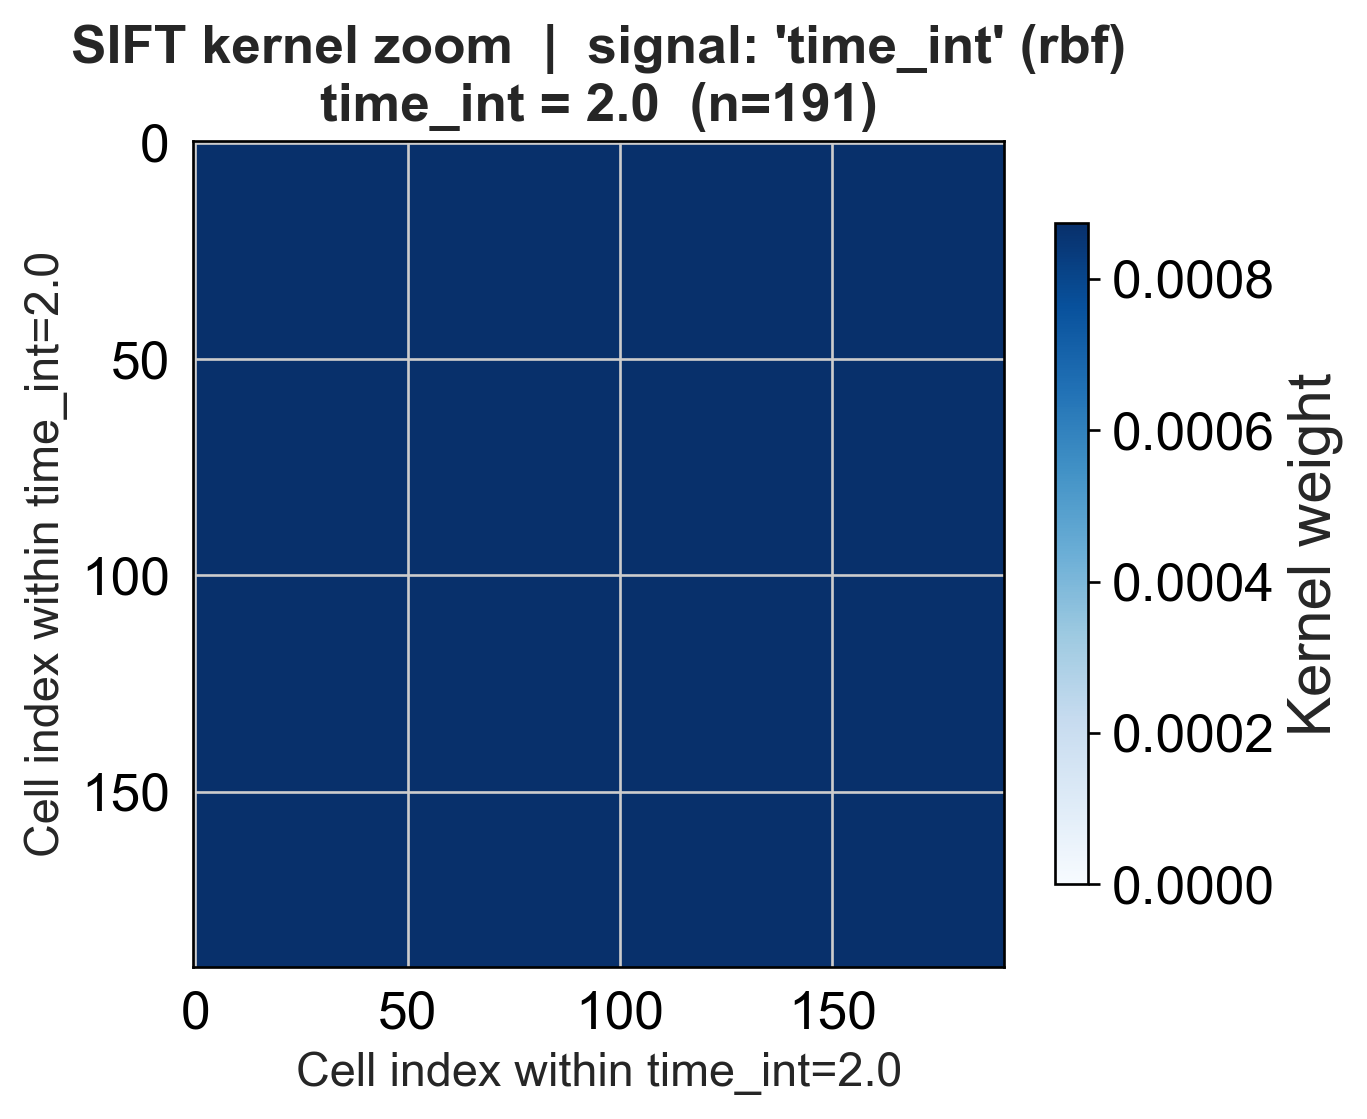

K_zoom shape: (191, 191)

First row:
[0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009
 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009
 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009
 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009
 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009
 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009
 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009
 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009 0.0009
 0.

In [9]:
_, K_zoom = plot_sift_kernel_zoom(
    adata,
    signal_key="time_int",
    groupby="time_int",
    zoom_label=2.0,
    metric="rbf",
    save_path=os.path.join(outdir, "kernel_zoom_2hpi.png"),
)
plt.show()

np.set_printoptions(precision=4, suppress=True, linewidth=120)
print(f"K_zoom shape: {K_zoom.shape}")
print(f"\nFirst row:\n{K_zoom[0]}")
print(f"\nLast row:\n{K_zoom[-1]}")

[plot_sift_kernel] RBF length_scale (median * 0.5): 0.003580
0.0035796056621330767


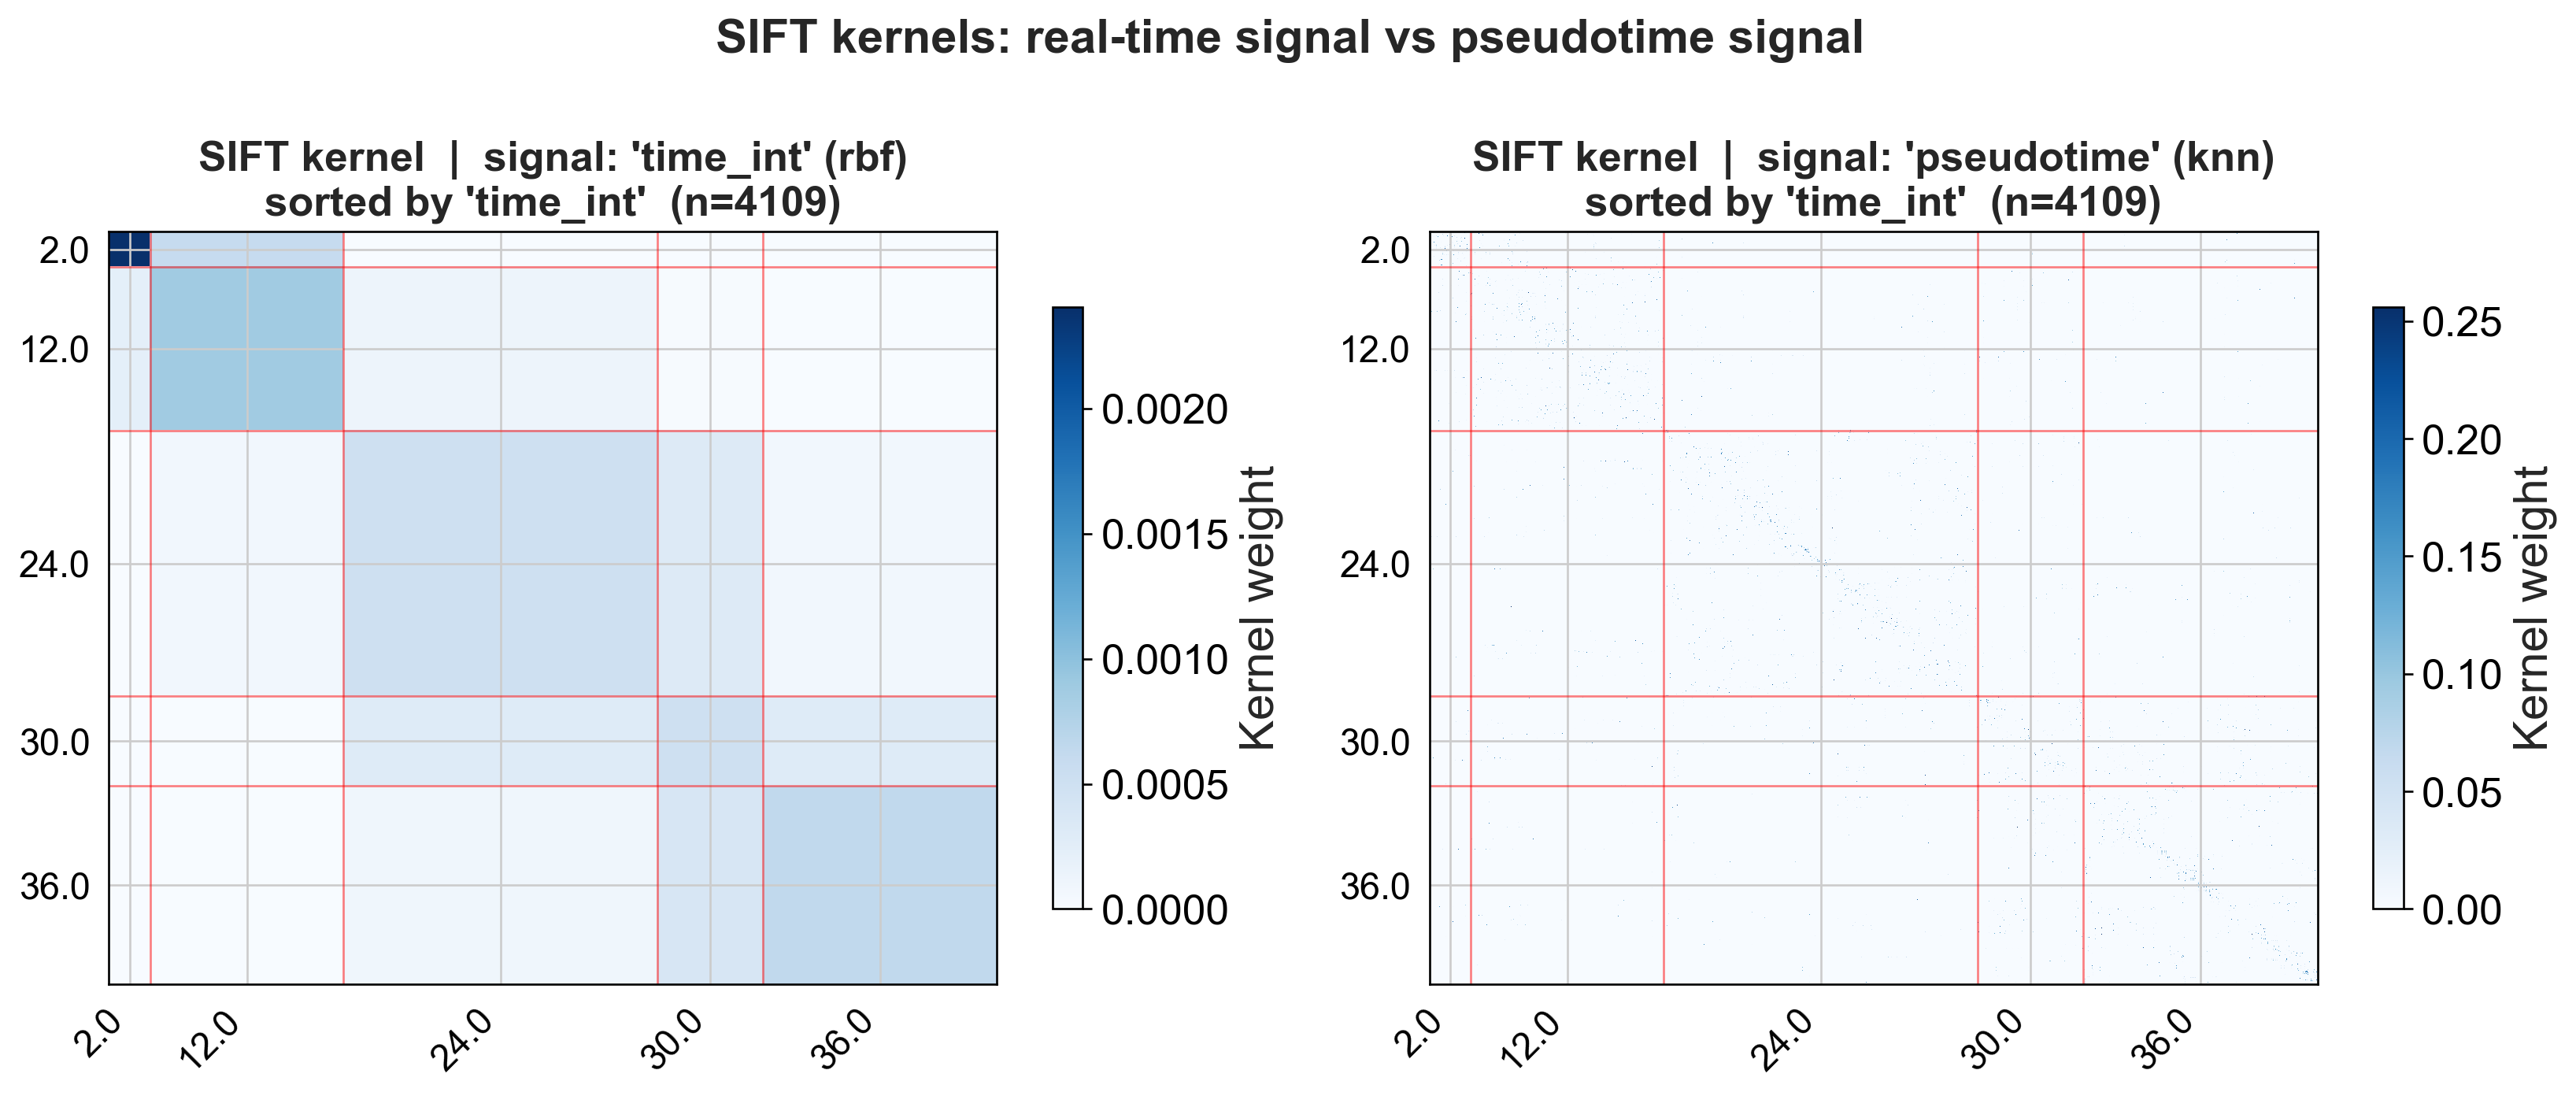

In [10]:
LENGTH_SCALE = None  # set to a float to override the median heuristic, e.g. 0.007
_kp = {"length_scale": LENGTH_SCALE} if LENGTH_SCALE is not None else None

# Both kernels side by side, full dataset, sorted by time_int
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
plot_sift_kernel(adata, signal_key="time_int",   groupby="time_int", metric="rbf", kernel_params=_kp, ax=axes[0])
plot_sift_kernel(adata, signal_key="pseudotime", groupby="time_int", metric="rbf", ax=axes[1])
plt.suptitle("SIFT kernels: real-time signal vs pseudotime signal", fontsize=18)
plt.tight_layout()
plt.savefig(os.path.join(outdir, "kernel_comparison.png"), bbox_inches="tight", dpi=150)
plt.show()

In [11]:
print("Cells per real time point:")
print(adata.obs["time_int"].value_counts().sort_index().to_string())

Cells per real time point:
time_int
2.0      191
12.0     894
24.0    1452
30.0     489
36.0    1083


In [12]:
# Inspect the first row of the time_int RBF kernel
_kp_inspect = {"length_scale": LENGTH_SCALE} if LENGTH_SCALE is not None else {}
if "length_scale" not in _kp_inspect:
    from scipy.spatial.distance import pdist as _pdist
    _sig = np.array(adata.obsm["time_int"], dtype=float)
    _d = _pdist(_sig)
    _kp_inspect["length_scale"] = float(np.median(_d[_d > 0]))
    print(f"Auto length_scale: {_kp_inspect['length_scale']:.6f}")

sft_inspect = SiFT(adata, kernel_key="time_int", metric="rbf", n_neighbors=15, kernel_params=_kp_inspect)
raw_k_inspect = sft_inspect._kernel(materialize=True, **sft_inspect._kernel_containers)
K_inspect = (raw_k_inspect.cpu().numpy() if hasattr(raw_k_inspect, "cpu") else np.array(raw_k_inspect)).astype(float)

np.set_printoptions(precision=4, suppress=True, linewidth=120)
row = K_inspect[2000]
print(f"K shape: {K_inspect.shape}")
print(f"First row (first 20 values): {row[:20]}")
vals, counts = np.unique(row.round(6), return_counts=True)
print("Unique values and counts:")
for v, c in zip(vals, counts):
    print(f"  {v:.6f}  x{c}")

Auto length_scale: 0.007159
K shape: (4109, 4109)
First row (first 20 values): [0.0002 0.0002 0.0002 0.0002 0.0002 0.0002 0.0002 0.0002 0.0002 0.0002 0.0002 0.0002 0.0002 0.0002 0.0002 0.0002 0.0002
 0.0002 0.0002 0.0002]
Unique values and counts:
  0.000007  x191
  0.000054  x894
  0.000241  x1452
  0.000350  x489
  0.000397  x1083


## 3. Run crisp

In [15]:
LENGTH_SCALE_B = None  # set to a float to override the median heuristic for time_int, e.g. 0.007

global_score = compute_projection_similarity(
    adata,
    signal_A=key_A,
    signal_B=key_B,
    embedding_key="X",
    metric_A="rbf",
    metric_B="rbf",
    device="cuda",
    kernel_params_B={"length_scale": LENGTH_SCALE_B} if LENGTH_SCALE_B is not None else None,
)
print(f"\nGlobal score: {global_score:.4f}")

[timing] PCA + neighbors:   0.97s
[crisp] RBF length_scale for 'pseudotime' (median * 0.5): 0.003875
0.0038746494271731935
[timing] SIFT signal A:     1.83s
[crisp] RBF length_scale for 'time_int' (median * 0.5): 0.003580
0.0035796056621330767
[timing] SIFT signal B:     1.44s
[timing] cell cosine:       0.35s
[timing] cell Spearman:     13.16s
[timing] cell Pearson:      0.48s
[timing] global Spearman:   55.15s
[timing] global Pearson:    0.23s
[timing] gene cosine+dot:   1.74s
[timing] cs_gene_score:     0.58s
Global projection similarity (pseudotime vs time_int): cosine=0.9812  spearman=0.9735  pearson=0.9770  mean_cell=0.9761

Global score: 0.9735


## 4. Compare cell score to abortive label

Only 36 hpi cells are labelled Abortive / Productive.  
We expect abortive cells to diverge from the pseudotime–realtime correspondence.

In [16]:
# Focus on 36 hpi cells where the abortive label is meaningful
adata = adata[adata.obs["abortive_state"].isin(["Abortive", "Productive"])].copy()
print(f"36 hpi cells: {adata.n_obs}")
print(adata.obs["abortive_state"].value_counts())

36 hpi cells: 4109
abortive_state
Productive    3875
Abortive       234
Name: count, dtype: int64


/tmp/ipykernel_2907822/3992818238.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


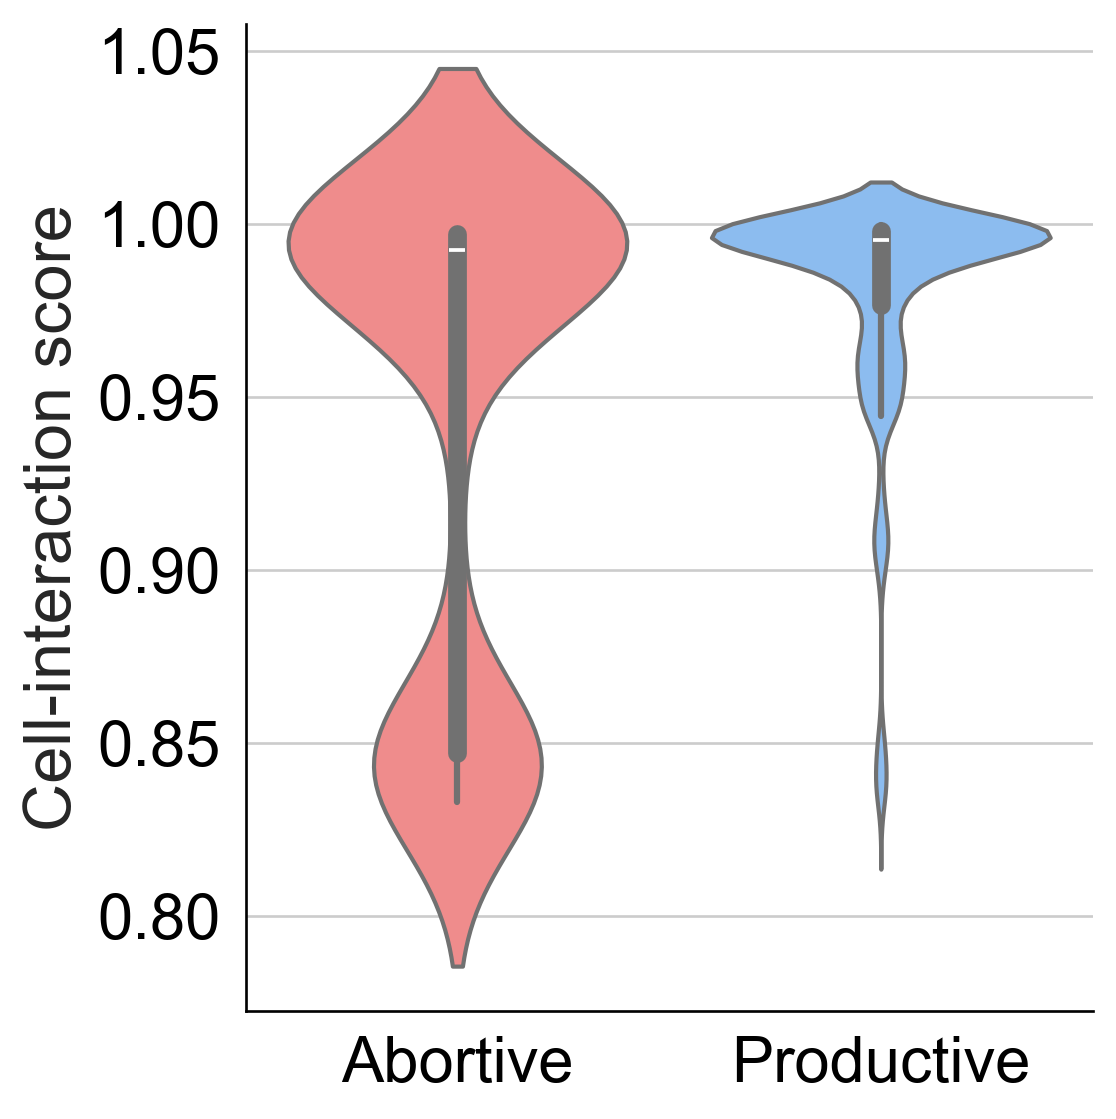

Abortive: 234 cells  |  Productive: 3875 cells


In [43]:
fig, ax = plt.subplots(figsize=(5, 5))

palette = {"Abortive": "#ff7c7b", "Productive": "#7bbcff"}

sns.violinplot(
    data=adata.obs,
    x="abortive_state", y="proj_pearson_cell",
    palette=palette, inner="box", ax=ax,
)

ab = adata.obs.loc[adata.obs["abortive_state"] == "Abortive",  "proj_pearson_cell"]
pr = adata.obs.loc[adata.obs["abortive_state"] == "Productive", "proj_pearson_cell"]
_, p = stats.ranksums(ab, pr)
# ax.set_title("Cell-interaction score of abortive and productive hepatocytes", fontsize=20)
ax.set_xlabel("", fontsize=20)
ax.set_ylabel("Cell-interaction score", fontsize=20)
ax.tick_params(axis="both", labelsize=19)

ax.set_frame_on(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(True)
ax.spines["bottom"].set_visible(True)
ax.tick_params(axis="both", which="both", length=4)

plt.tight_layout()
plt.savefig(os.path.join(outdir, "crisp_abortive_violin.png"), bbox_inches="tight")
plt.show()

num_ab = (adata.obs["abortive_state"] == "Abortive").sum()
num_pr = (adata.obs["abortive_state"] == "Productive").sum()
print(f"Abortive: {num_ab} cells  |  Productive: {num_pr} cells")

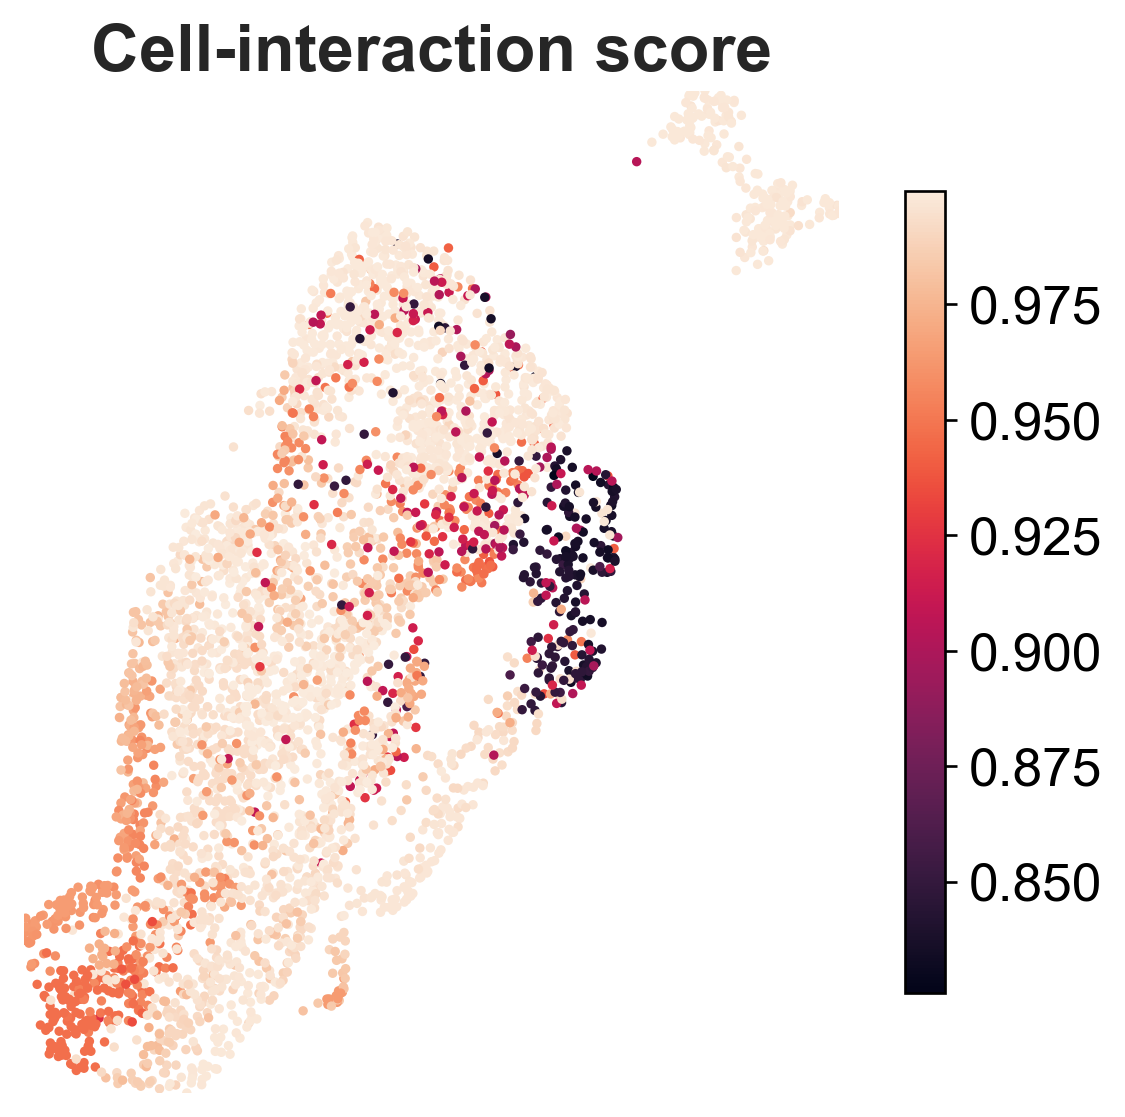

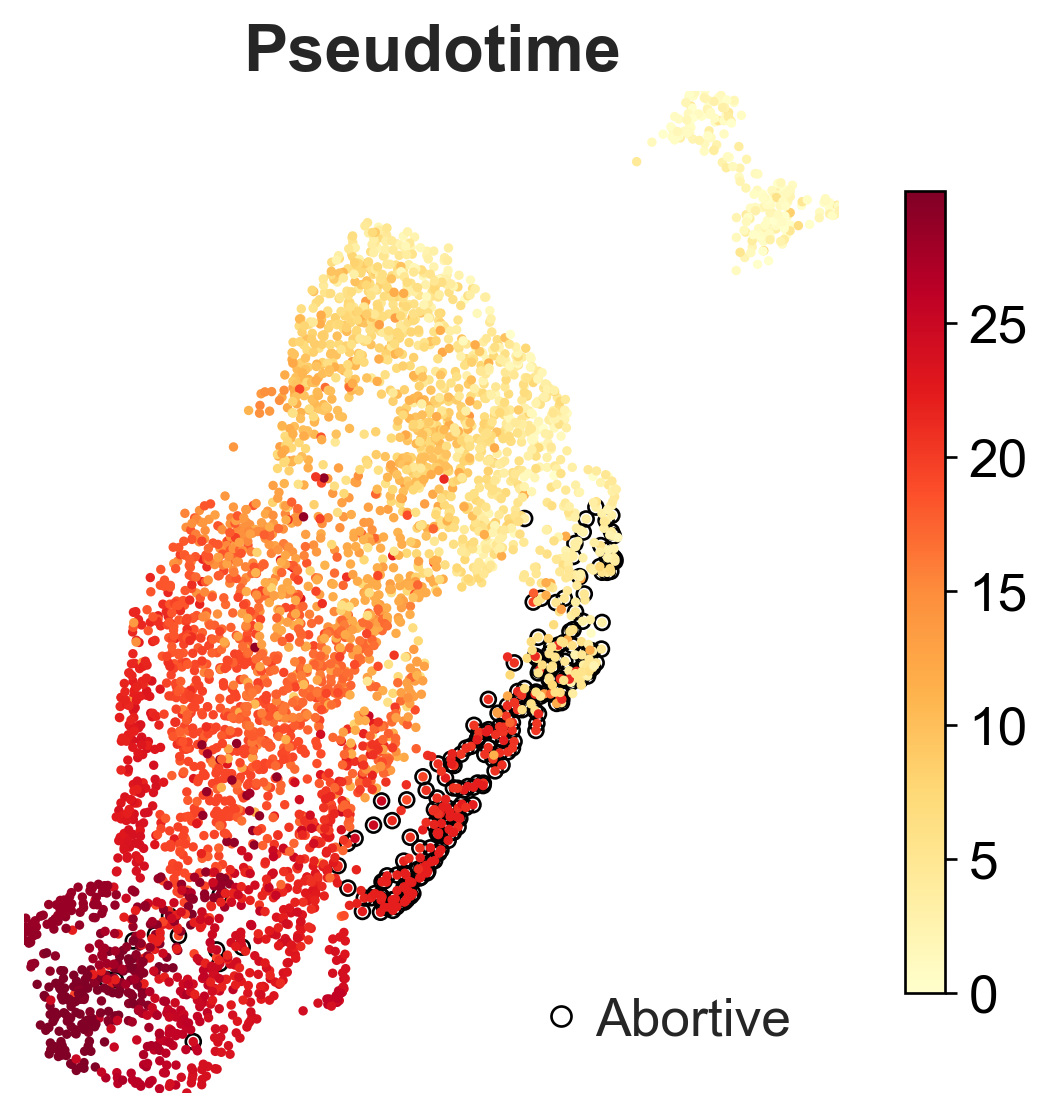

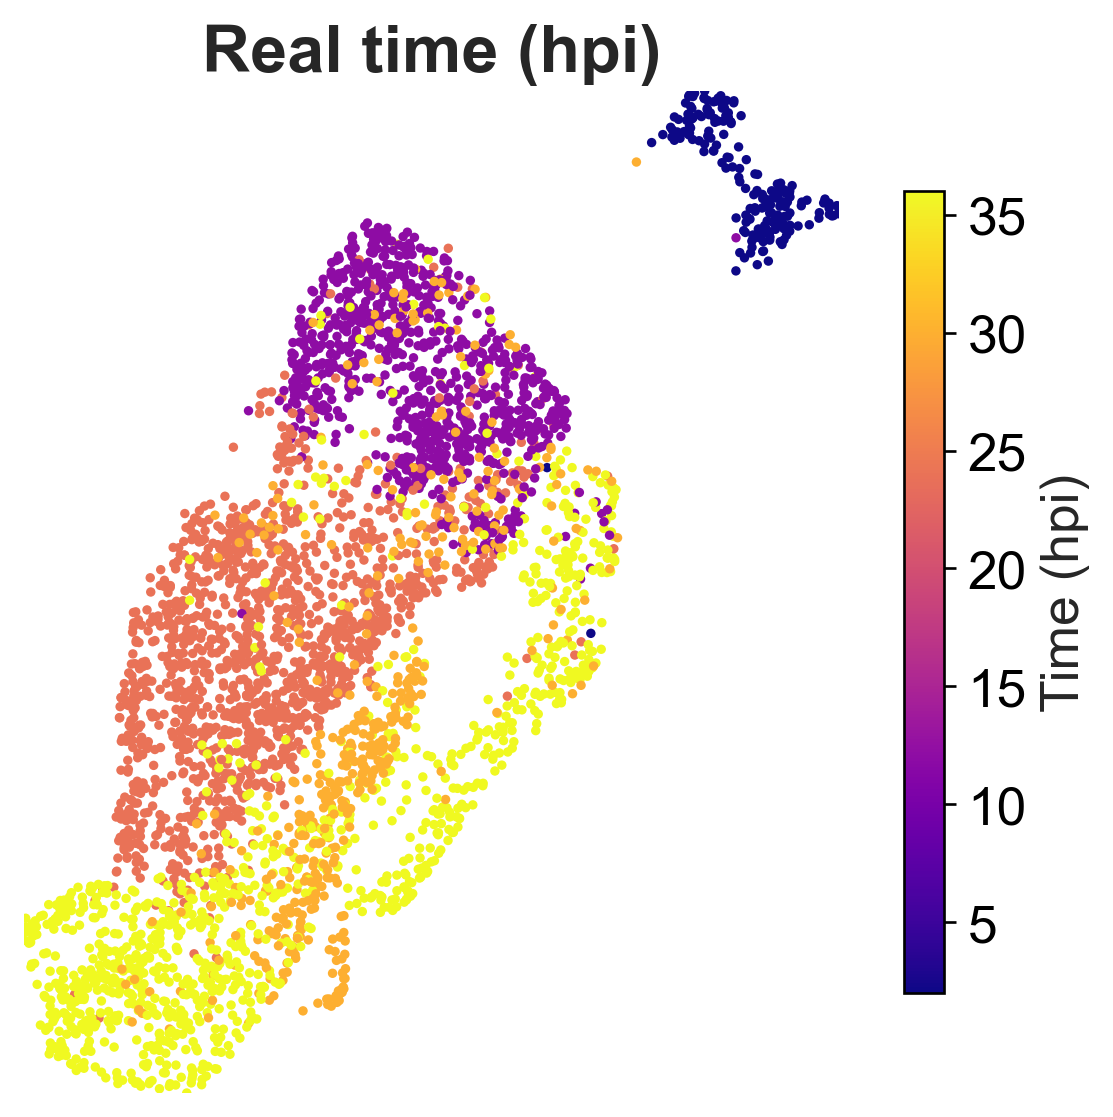

In [18]:
from scipy.stats import gaussian_kde
import matplotlib.lines as mlines

umap = adata.obsm["X_umap"]
xlim = (umap[:, 0].min(), umap[:, 0].max())
ylim = (umap[:, 1].min(), umap[:, 1].max())
abt = (adata.obs["abortive_state"] == "Abortive").values

def _style_ax(ax, title):
    ax.set_title(title, fontsize=20)
    ax.set_xlim(xlim); ax.set_ylim(ylim)
    ax.set_aspect("equal"); ax.set_axis_off()

def _cbar(mappable, ax):
    cb = plt.colorbar(mappable, ax=ax, shrink=0.8)
    cb.ax.tick_params(labelsize=16)
    return cb

# --- 1. Spearman cell score ---
fig, ax = plt.subplots(figsize=(6, 5))
sc1 = ax.scatter(umap[:, 0], umap[:, 1], c=adata.obs["proj_pearson_cell"],
                 cmap="rocket", s=8, linewidths=0, rasterized=True)
_cbar(sc1, ax)
_style_ax(ax, "Cell-interaction score")
plt.tight_layout()
plt.savefig(os.path.join(outdir, "crisp_umap_cell_score.png"), bbox_inches="tight")
plt.show()

# --- 2. Pseudotime (abortive rings below color) ---
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(umap[abt, 0], umap[abt, 1], facecolors="none", edgecolors="black",
           linewidths=0.8, s=20, zorder=1)
sc2 = ax.scatter(umap[:, 0], umap[:, 1], c=adata.obs["pseudotime"],
                 cmap="YlOrRd", s=8, linewidths=0, rasterized=True, zorder=2)
_cbar(sc2, ax)
legend_handle = mlines.Line2D([], [], marker="o", color="none",
                               markeredgecolor="black", markeredgewidth=0.8,
                               markersize=6, label="Abortive")
ax.legend(handles=[legend_handle], frameon=False, fontsize=16, loc="lower right")
_style_ax(ax, "Pseudotime")
plt.tight_layout()
plt.savefig(os.path.join(outdir, "crisp_umap_pseudotime.png"), bbox_inches="tight")
plt.show()

# --- 3. Real time (continuous gradient, shared with the pseudotime-vs-score plot below) ---
TIME_CMAP = "plasma"
time_vmin, time_vmax = adata.obs["time_int"].min(), adata.obs["time_int"].max()

fig, ax = plt.subplots(figsize=(6, 5))
sc3 = ax.scatter(umap[:, 0], umap[:, 1], c=adata.obs["time_int"],
                 cmap=TIME_CMAP, vmin=time_vmin, vmax=time_vmax,
                 s=8, linewidths=0, rasterized=True)
cb3 = _cbar(sc3, ax)
cb3.set_label("Time (hpi)", fontsize=16)
_style_ax(ax, "Real time (hpi)")
plt.tight_layout()
plt.savefig(os.path.join(outdir, "crisp_umap_realtime.png"), bbox_inches="tight")
plt.show()


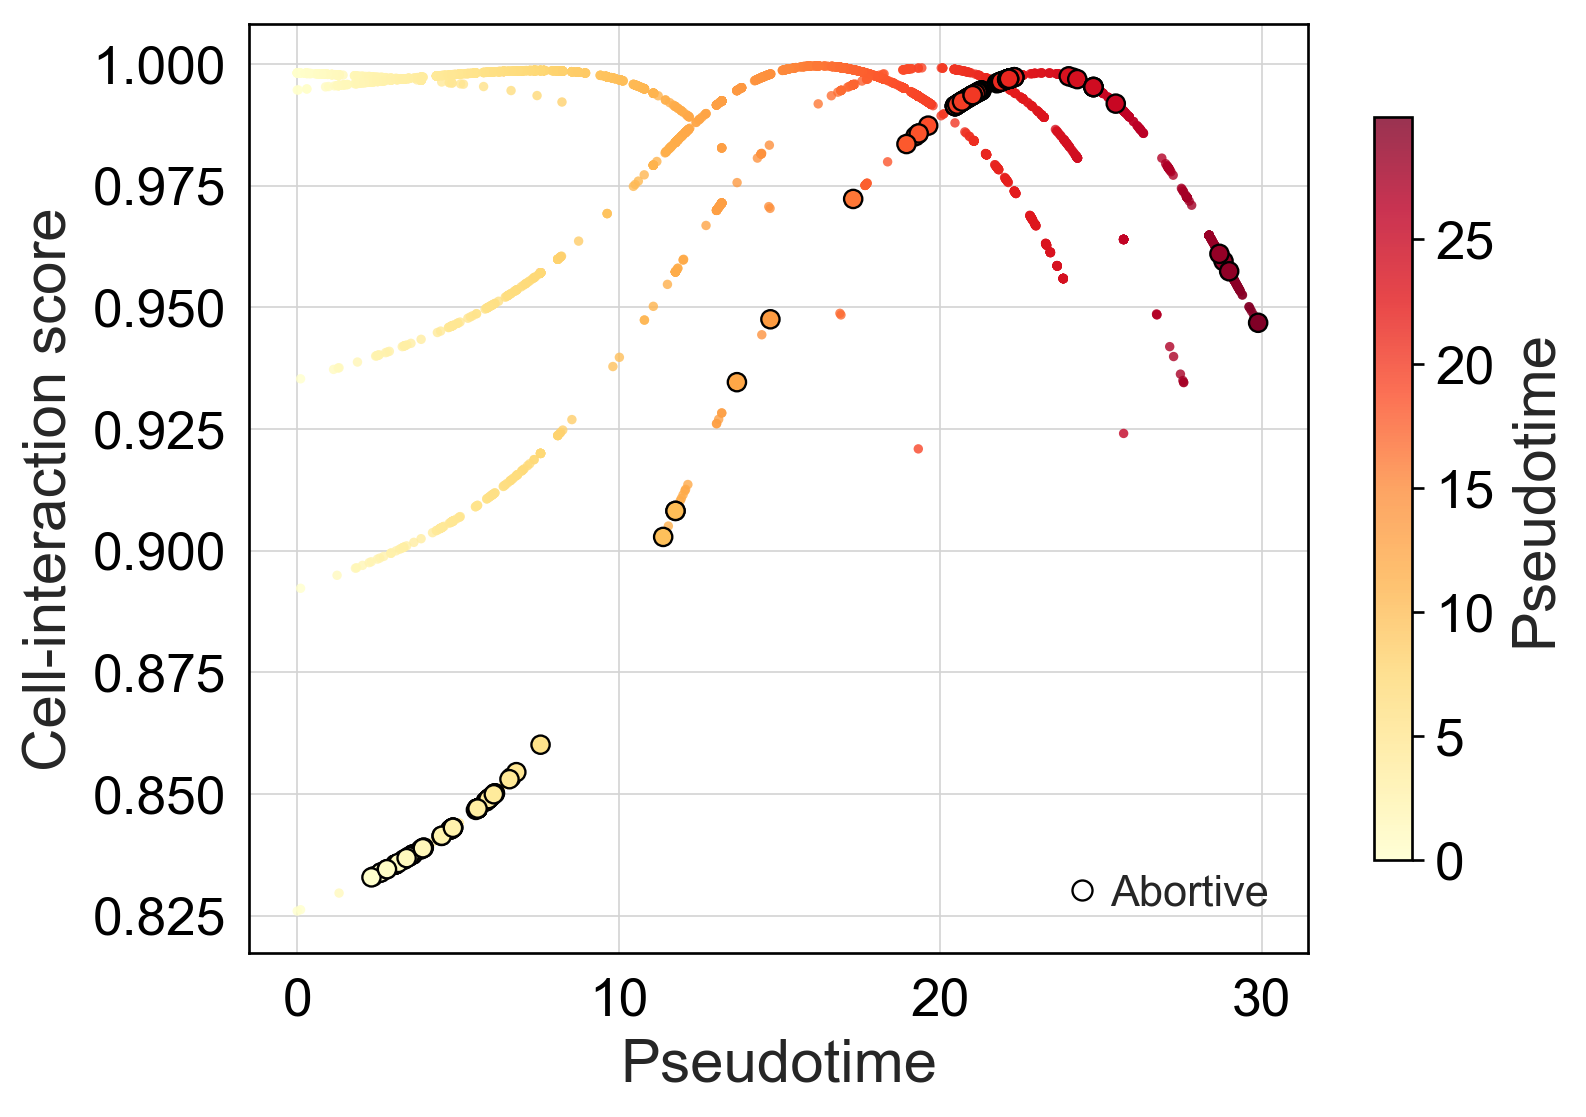

In [44]:
pt  = adata.obs["pseudotime"].values
sc_ = adata.obs["proj_pearson_cell"].values
abt = (adata.obs["abortive_state"] == "Abortive").values
pro = ~abt

fig, ax = plt.subplots(figsize=(7, 5))
ax.set_facecolor("white")
ax.grid(True, color="lightgrey", linewidth=0.5, zorder=0)

sc_pro = ax.scatter(pt[pro], sc_[pro], c=pt[pro], cmap="YlOrRd",
                    s=8, linewidths=0, alpha=0.8, rasterized=True, zorder=2)

ax.scatter(pt[abt], sc_[abt], c=pt[abt], cmap="YlOrRd",
           edgecolors="black", linewidths=0.7, s=30, zorder=3)

plt.colorbar(sc_pro, ax=ax, label="Pseudotime", shrink=0.8)

legend_handle = mlines.Line2D([], [], marker="o", color="none",
                               markeredgecolor="black", markeredgewidth=0.7,
                               markersize=6, label="Abortive")
ax.legend(handles=[legend_handle], frameon=False, fontsize=13)

ax.set_xlabel("Pseudotime")
ax.set_ylabel("Cell-interaction score")
# ax.set_title("Cell-interaction score and pseudotime (")
plt.tight_layout()
plt.savefig(os.path.join(outdir, "score_vs_pseudotime_abortive.png"), bbox_inches="tight")
plt.show()


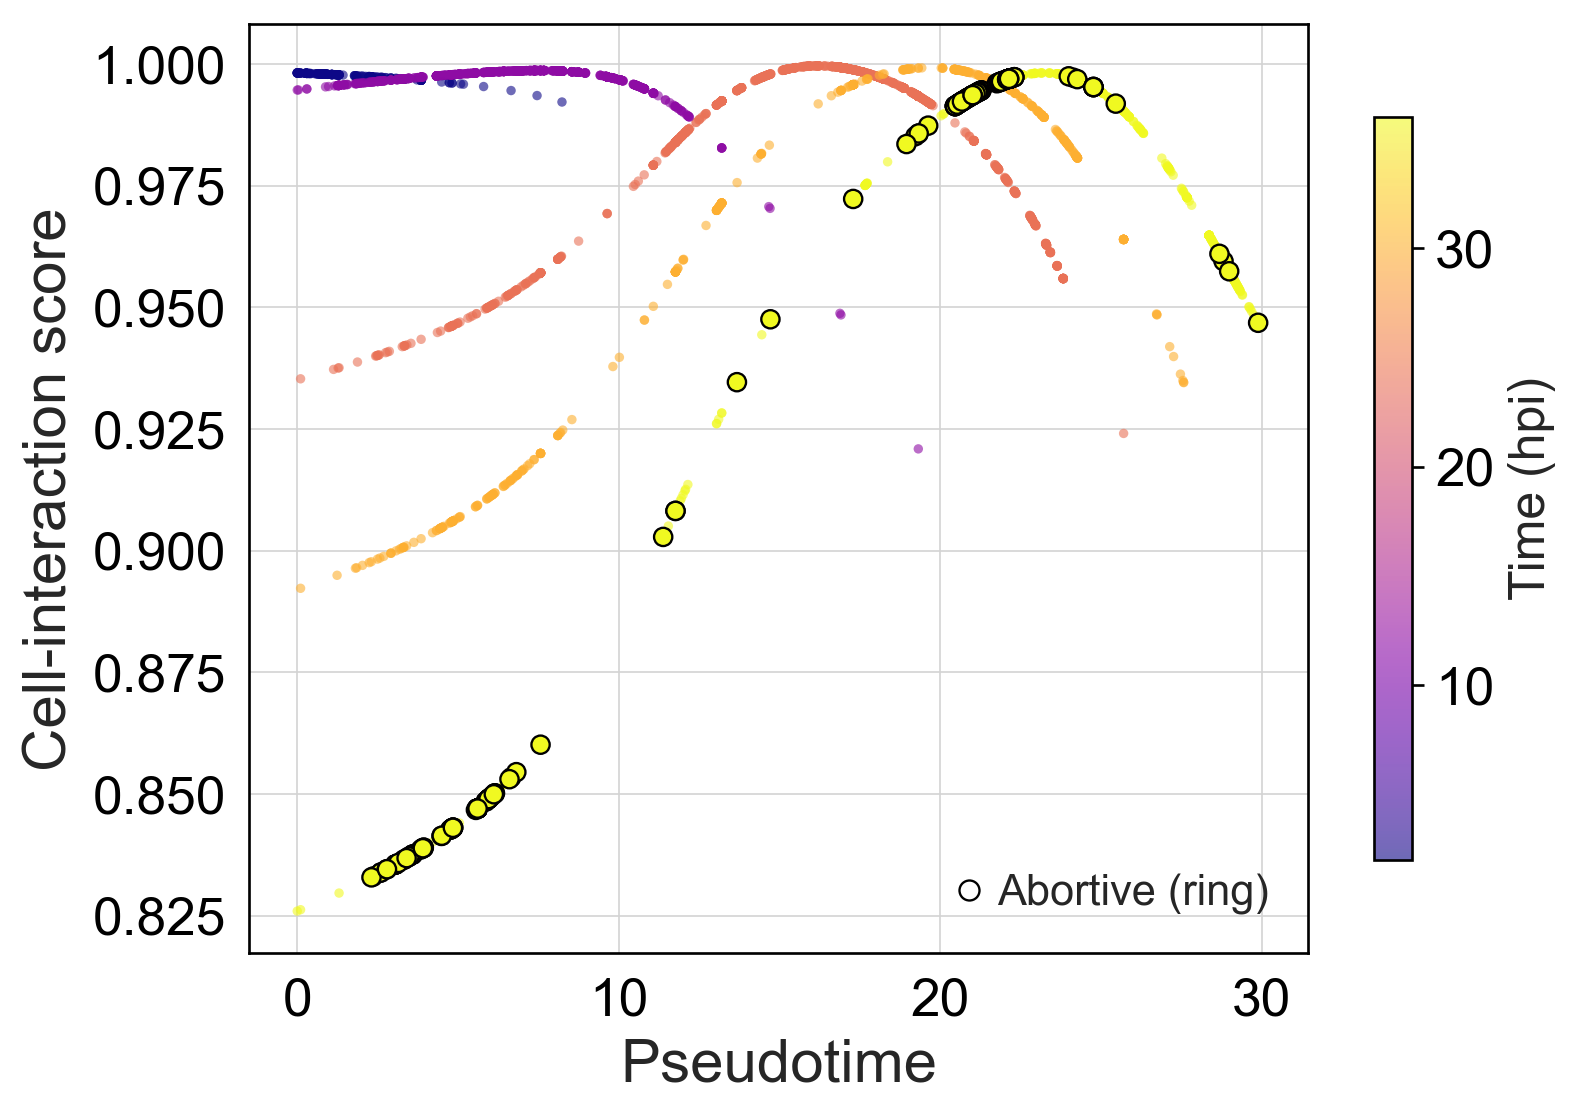

In [47]:
pt  = adata.obs["pseudotime"].values
sc_ = adata.obs["proj_pearson_cell"].values
ti  = adata.obs["time_int"].values
abt = (adata.obs["abortive_state"] == "Abortive").values
pro = ~abt

fig, ax = plt.subplots(figsize=(7, 5))
ax.set_facecolor("white")
ax.grid(True, color="lightgrey", linewidth=0.5, zorder=0)

sc_pro = ax.scatter(pt[pro], sc_[pro], c=ti[pro], cmap=TIME_CMAP, vmin=time_vmin, vmax=time_vmax,
                     s=8, linewidths=0, alpha=0.6, rasterized=True, zorder=2)

# Abortive cells: colored by time + black outline
ax.scatter(pt[abt], sc_[abt], c=ti[abt], cmap=TIME_CMAP, vmin=time_vmin, vmax=time_vmax,
           edgecolors="black", linewidths=0.7, s=30, zorder=3)

cb = plt.colorbar(sc_pro, ax=ax, shrink=0.8)
cb.set_label("Time (hpi)", fontsize=15)

legend_handle = mlines.Line2D([], [], marker="o", color="none",
                               markeredgecolor="black", markeredgewidth=0.7,
                               markersize=6, label="Abortive (ring)")
ax.legend(handles=[legend_handle], frameon=False, fontsize=13, loc="lower right")

ax.set_xlabel("Pseudotime")
ax.set_ylabel("Cell-interaction score")
# ax.set_title("Cell-interaction score vs pseudotime  (colored by real time)")
plt.tight_layout()
plt.savefig(os.path.join(outdir, "score_vs_pseudotime_realtime_colored.png"), bbox_inches="tight")
plt.show()

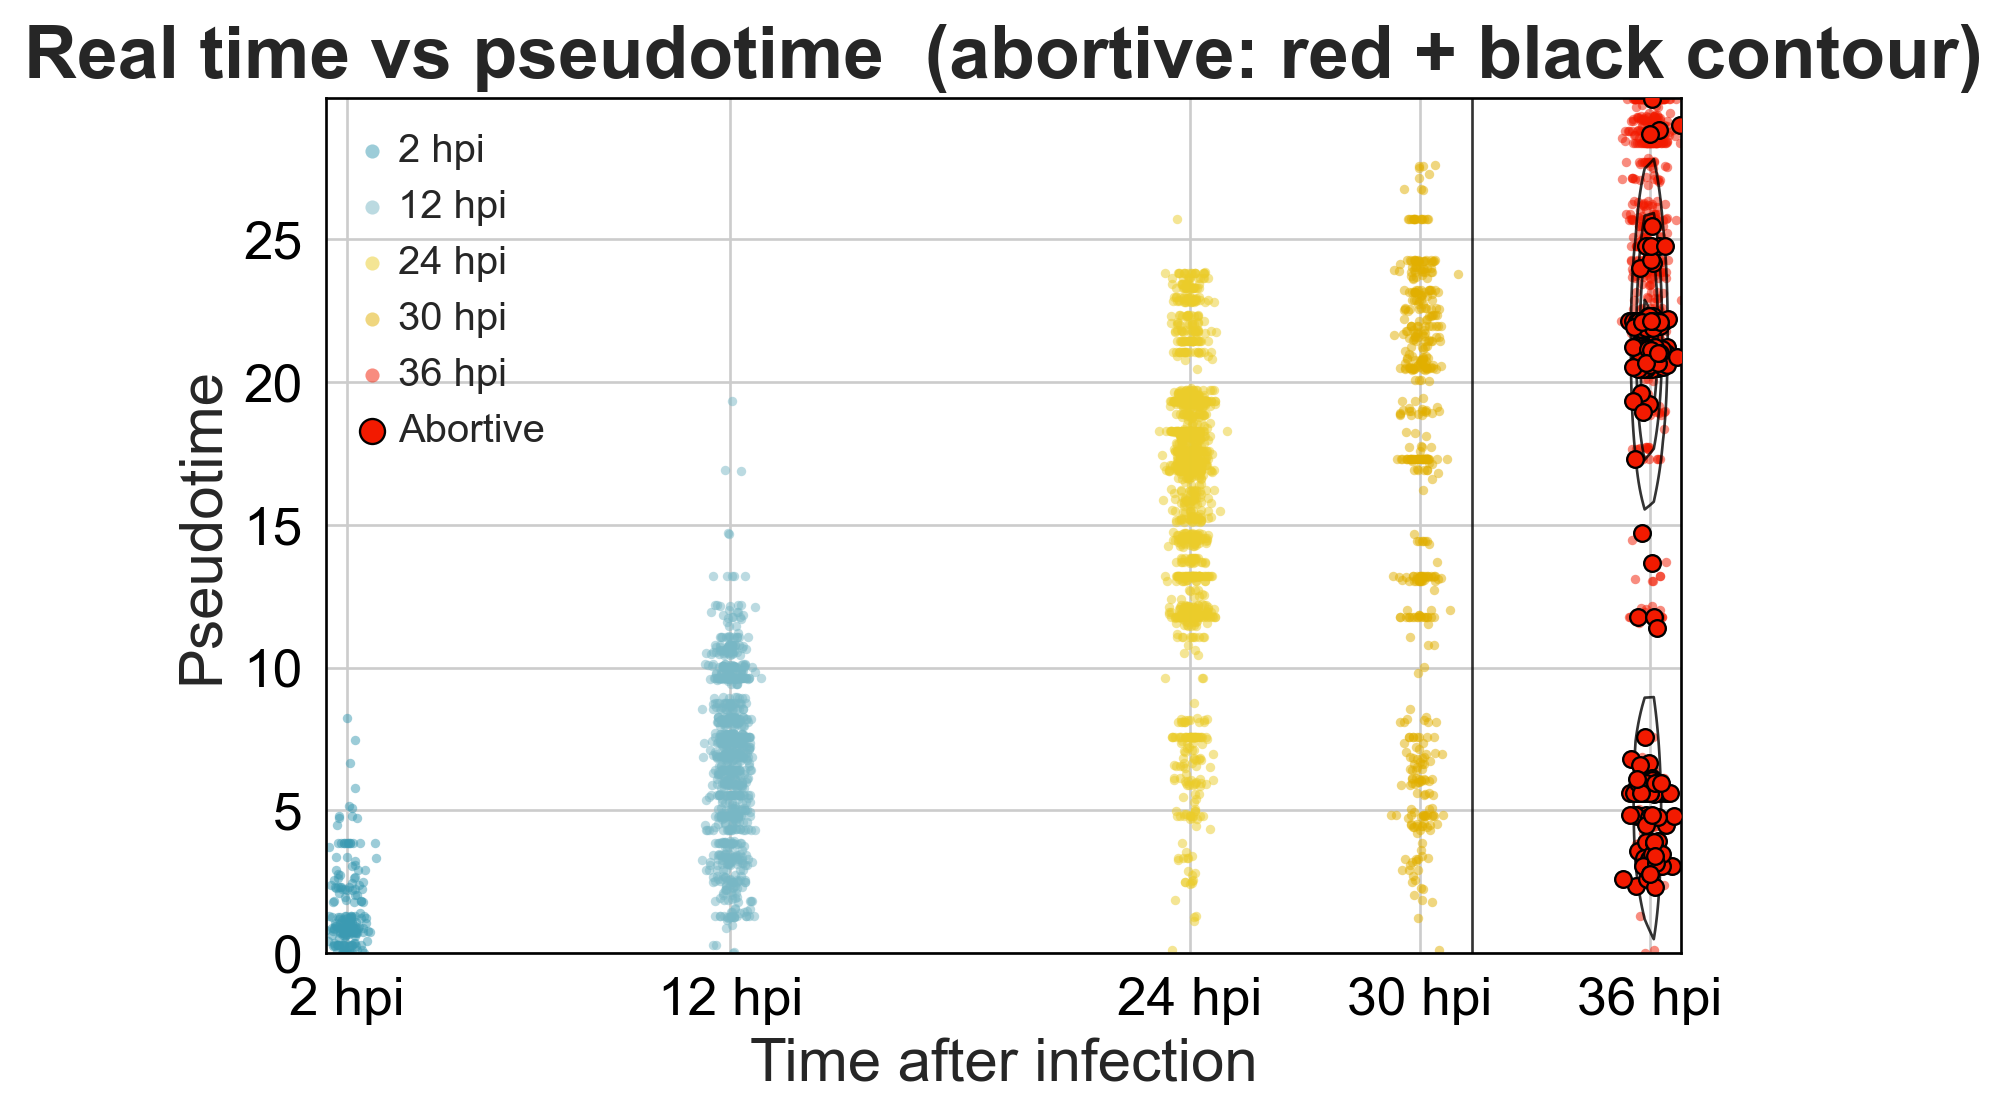

In [24]:
from scipy.stats import gaussian_kde

zissou1 = {"2 hpi": "#3B9AB2", "12 hpi": "#78B7C5", "24 hpi": "#EBCC2A",
           "30 hpi": "#E1AF00", "36 hpi": "#F21A00"}
time_label_map = {2.0: "2 hpi", 12.0: "12 hpi", 24.0: "24 hpi",
                  30.0: "30 hpi", 36.0: "36 hpi"}

np.random.seed(42)
jitter = np.random.normal(0, 0.25, adata.n_obs)
x = adata.obs["time_int"].values + jitter
y = adata.obs["pseudotime"].values
abt = (adata.obs["abortive_state"] == "Abortive").values

fig, ax = plt.subplots(figsize=(7, 5))

# All cells coloured by time point
for t, label in time_label_map.items():
    mask = adata.obs["time_int"].values == t
    ax.scatter(x[mask], y[mask], c=zissou1[label], s=8, alpha=0.5,
               linewidths=0, label=label, rasterized=True)

# Abortive cells: red fill + black outline
ax.scatter(x[abt], y[abt], c="#F21A00", edgecolors="black",
           linewidths=0.7, s=25, zorder=5, label="Abortive")

# KDE contour around abortive cells
kde = gaussian_kde(np.vstack([x[abt], y[abt]]))
xi = np.linspace(x.min(), x.max(), 150)
yi = np.linspace(y.min(), y.max(), 150)
Xi, Yi = np.meshgrid(xi, yi)
Zi = kde(np.vstack([Xi.ravel(), Yi.ravel()])).reshape(Xi.shape)
ax.contour(Xi, Yi, Zi, levels=4, colors="black", linewidths=0.8, alpha=0.8)

ax.set_xticks(list(time_label_map.keys()))
ax.set_xticklabels(list(time_label_map.values()))
ax.set_xlabel("Time after infection")
ax.set_ylabel("Pseudotime")
ax.set_title("Real time vs pseudotime  (abortive: red + black contour)")
ax.legend(frameon=False, fontsize=12, markerscale=1.5)
plt.tight_layout()
plt.savefig(os.path.join(outdir, "time_vs_pseudotime_abortive.png"), bbox_inches="tight")
plt.show()

In [25]:
score_col = "proj_pearson_cell"
threshold = 0.5

low  = adata.obs[adata.obs[score_col] <  threshold]
high = adata.obs[adata.obs[score_col] >= threshold]
bg_rate = (adata.obs["abortive_state"] == "Abortive").mean()

for group, df in [("< 0.5", low), (">= 0.5", high)]:
    n = len(df)
    n_ab = (df["abortive_state"] == "Abortive").sum()
    enrich = (n_ab / n) / bg_rate if n > 0 else float("nan")
    print(f"Score {group}:  n={n}  |  Abortive: {n_ab} ({100*n_ab/n:.1f}%)  |  Enrichment: {enrich:.1f}x")

print(f"\nBackground abortive rate: {100*bg_rate:.1f}%")

Score < 0.5:  n=0  |  Abortive: 0 (nan%)  |  Enrichment: nanx
Score >= 0.5:  n=4109  |  Abortive: 234 (5.7%)  |  Enrichment: 1.0x

Background abortive rate: 5.7%


/tmp/ipykernel_2907822/402035386.py:12: RuntimeWarning: invalid value encountered in scalar divide
  print(f"Score {group}:  n={n}  |  Abortive: {n_ab} ({100*n_ab/n:.1f}%)  |  Enrichment: {enrich:.1f}x")


## 5. PBA count fraction by cell score — 36 hpi only

/tmp/ipykernel_2907822/2868067.py:18: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  _, p = stats.ranksums(low_vals, high_vals)
/tmp/ipykernel_2907822/2868067.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


36 hpi cells: 1083
score_group
≥ 0.5    1083
Name: count, dtype: int64


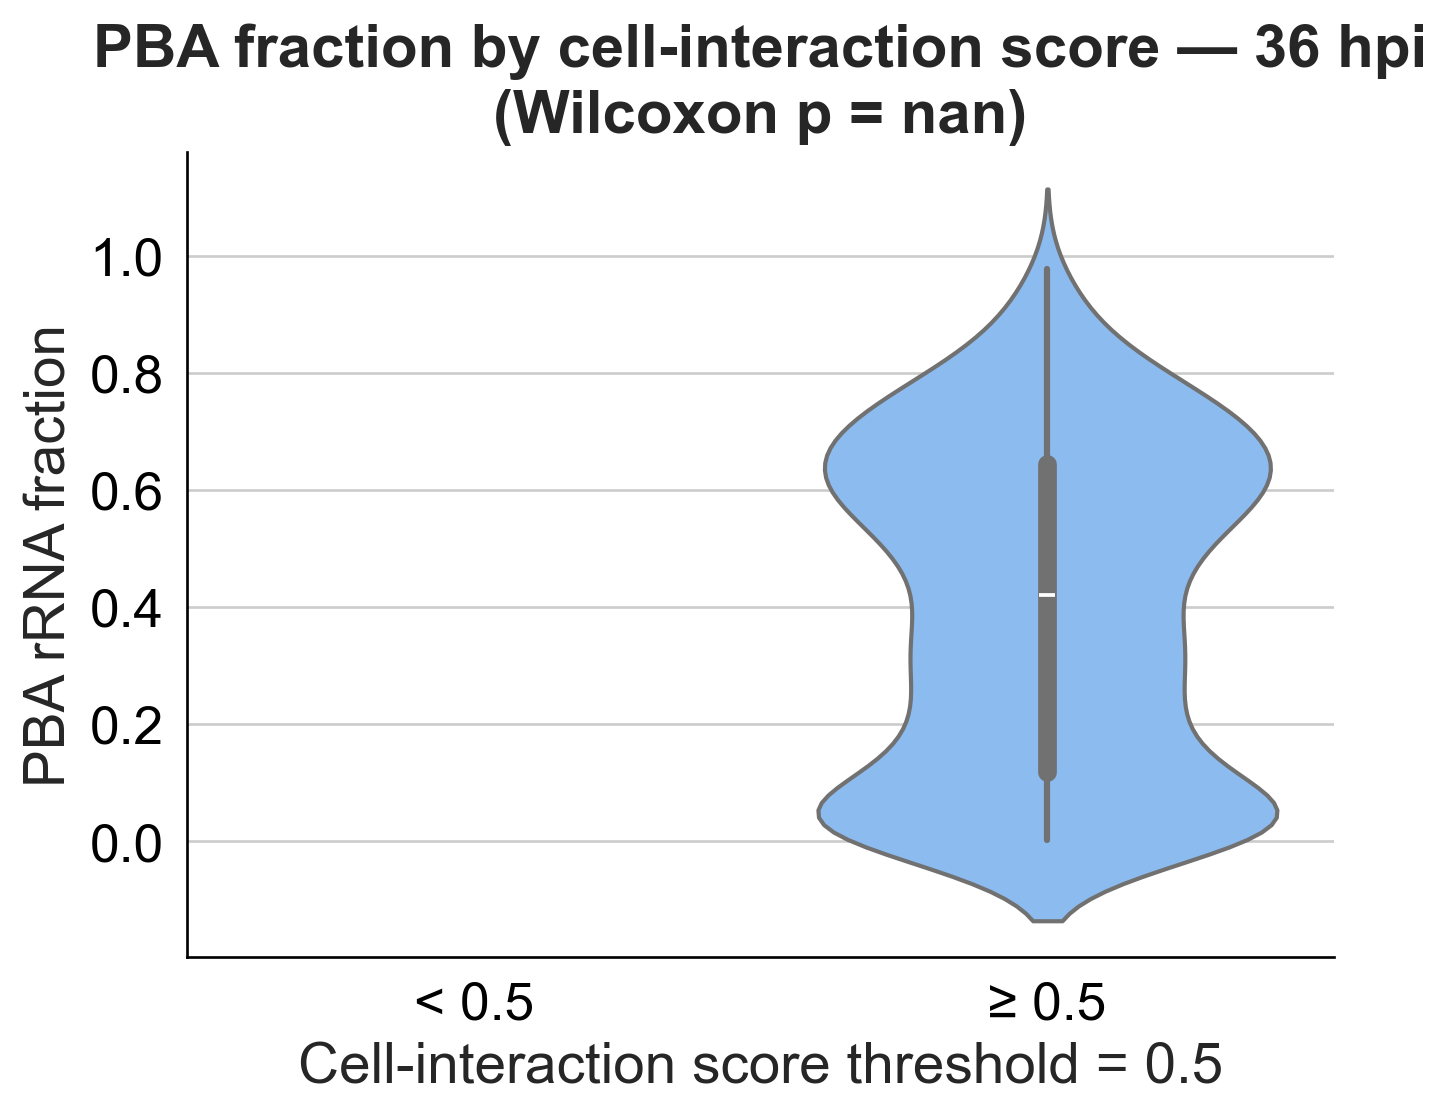


Below threshold: n=0,  median PBA fraction = nan
Above threshold: n=1083,  median PBA fraction = 0.4213


In [26]:
SCORE_THRESHOLD = 0.5
PBA_COL         = "normalized_PBA"


adata_36 = adata[adata.obs["time_int"] == 36.0].copy()
print(f"36 hpi cells: {adata_36.n_obs}")

low_label  = f"< {SCORE_THRESHOLD}"
high_label = f"≥ {SCORE_THRESHOLD}"
adata_36.obs["score_group"] = np.where(
    adata_36.obs["proj_pearson_cell"] < SCORE_THRESHOLD,
    low_label, high_label
)
print(adata_36.obs["score_group"].value_counts())

low_vals  = adata_36.obs.loc[adata_36.obs["score_group"] == low_label,  PBA_COL]
high_vals = adata_36.obs.loc[adata_36.obs["score_group"] == high_label, PBA_COL]
_, p = stats.ranksums(low_vals, high_vals)

fig, ax = plt.subplots(figsize=(6, 5))
palette = {low_label: "#ff7c7b", high_label: "#7bbcff"}
sns.violinplot(
    data=adata_36.obs,
    x="score_group", y=PBA_COL,
    order=[low_label, high_label],
    palette=palette, inner="box", ax=ax,
)
ax.set_title(f"PBA fraction by cell-interaction score — 36 hpi\n(Wilcoxon p = {p:.2e})", fontsize=18)
ax.set_xlabel(f"Cell-interaction score threshold = {SCORE_THRESHOLD}", fontsize=17)
ax.set_ylabel("PBA rRNA fraction", fontsize=17)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(os.path.join(outdir, "violin_pba_fraction_by_score_36hpi.png"), dpi=150, bbox_inches="tight")
plt.show()

print(f"\nBelow threshold: n={len(low_vals)},  median PBA fraction = {low_vals.median():.4f}")
print(f"Above threshold: n={len(high_vals)},  median PBA fraction = {high_vals.median():.4f}")

/tmp/ipykernel_2907822/3692872712.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


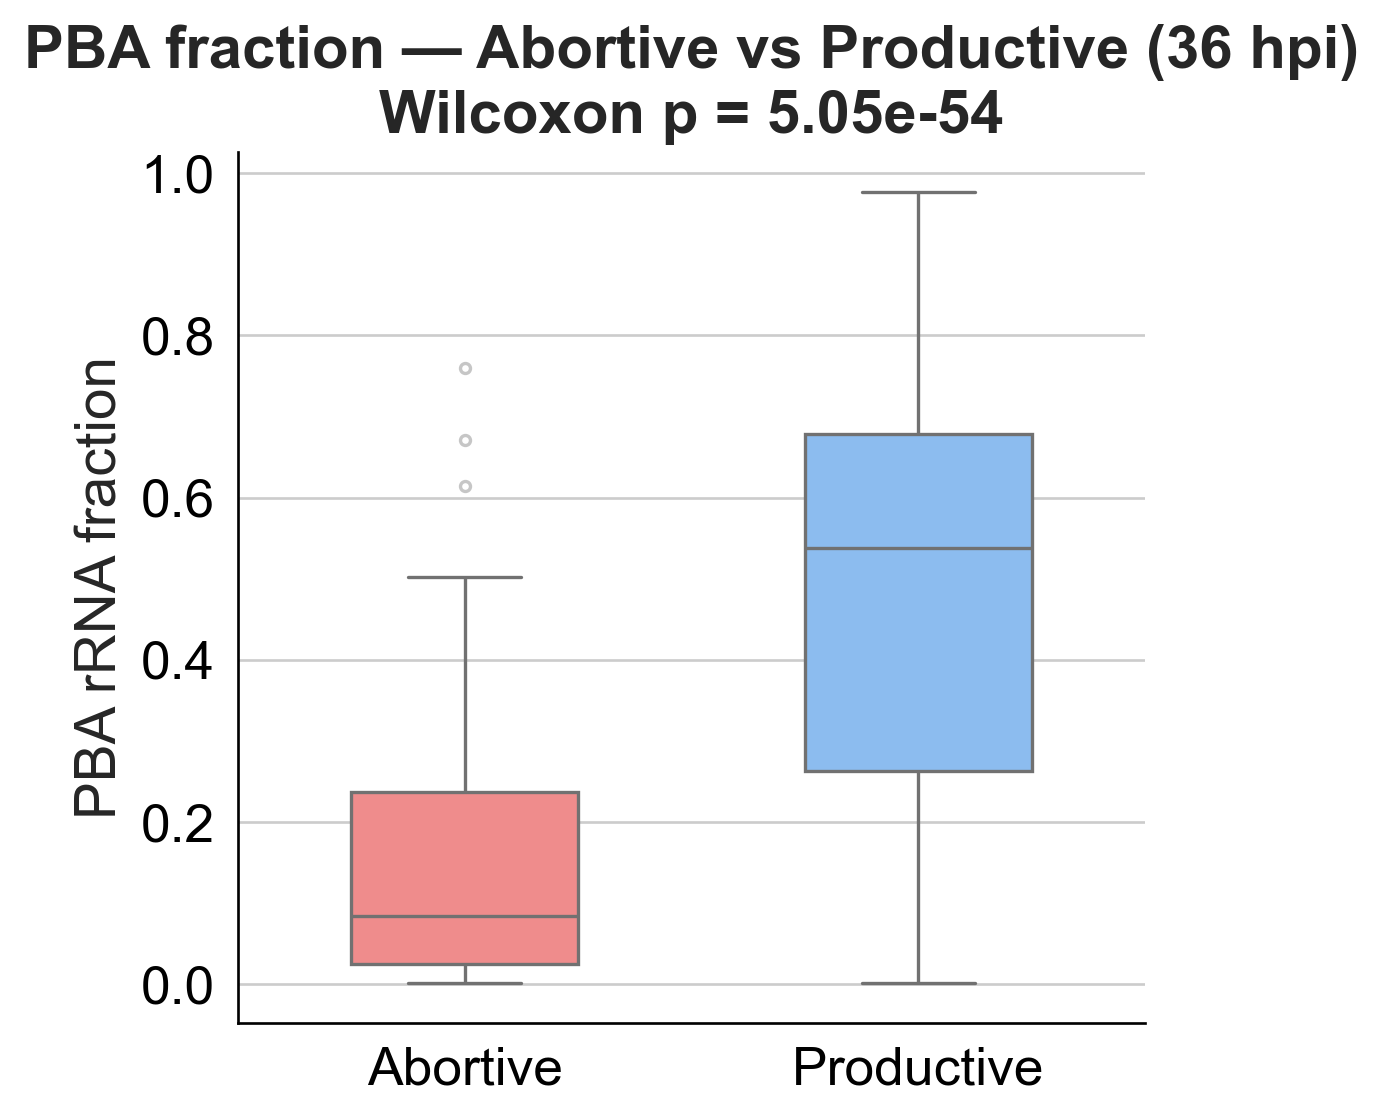

Abortive  (n=234):  median = 0.0845
Productive (n=849): median = 0.5375


In [27]:
ab_vals = adata_36.obs.loc[adata_36.obs["abortive_state"] == "Abortive",  PBA_COL]
pr_vals = adata_36.obs.loc[adata_36.obs["abortive_state"] == "Productive", PBA_COL]
_, p = stats.ranksums(ab_vals, pr_vals)

fig, ax = plt.subplots(figsize=(5, 5))
palette = {"Abortive": "#ff7c7b", "Productive": "#7bbcff"}
sns.boxplot(
    data=adata_36.obs,
    x="abortive_state", y=PBA_COL,
    order=["Abortive", "Productive"],
    palette=palette, width=0.5, ax=ax,
    flierprops=dict(marker="o", markersize=3, alpha=0.4),
)
ax.set_title(f"PBA fraction — Abortive vs Productive (36 hpi)\nWilcoxon p = {p:.2e}", fontsize=18)
ax.set_xlabel("", fontsize=17)
ax.set_ylabel("PBA rRNA fraction", fontsize=17)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(os.path.join(outdir, "boxplot_pba_fraction_abortive_36hpi.png"), dpi=150, bbox_inches="tight")
plt.show()

print(f"Abortive  (n={len(ab_vals)}):  median = {ab_vals.median():.4f}")
print(f"Productive (n={len(pr_vals)}): median = {pr_vals.median():.4f}")

## 6. PBA fraction by cell score — 24 & 30 hpi

24+36 hpi cells: 1941
time_int
24.0    1452
30.0     489
Name: count, dtype: int64

Score group counts:
score_group
≥ 0.9    1927
< 0.9      14
Name: count, dtype: int64


/tmp/ipykernel_2907822/2794722373.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


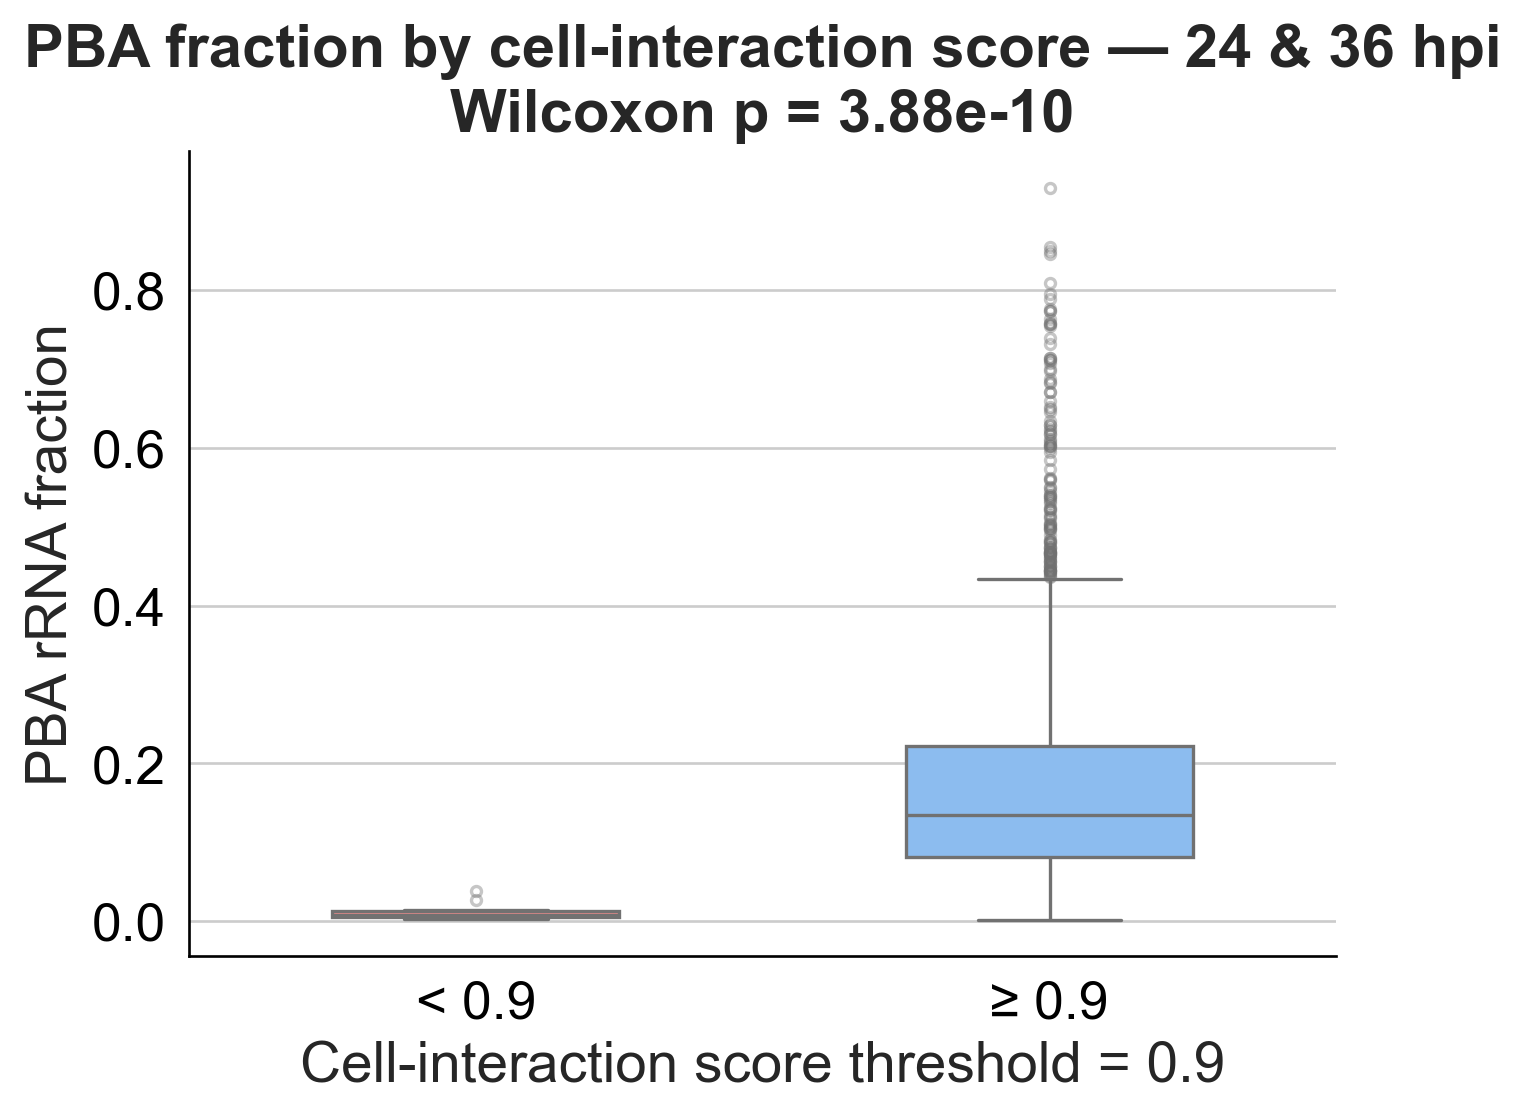


Below threshold (n=14):  median = 0.0082
Above threshold (n=1927): median = 0.1342


In [28]:
SCORE_THRESHOLD = 0.9

adata_2430 = adata[adata.obs["time_int"].isin([24.0, 30.0])].copy()
print(f"24+36 hpi cells: {adata_2430.n_obs}")
print(adata_2430.obs["time_int"].value_counts().sort_index())

low_label  = f"< {SCORE_THRESHOLD}"
high_label = f"≥ {SCORE_THRESHOLD}"
adata_2430.obs["score_group"] = np.where(
    adata_2430.obs["proj_pearson_cell"] < SCORE_THRESHOLD,
    low_label, high_label
)
print("\nScore group counts:")
print(adata_2430.obs["score_group"].value_counts())

low_vals  = adata_2430.obs.loc[adata_2430.obs["score_group"] == low_label,  PBA_COL]
high_vals = adata_2430.obs.loc[adata_2430.obs["score_group"] == high_label, PBA_COL]
_, p = stats.ranksums(low_vals, high_vals)

fig, ax = plt.subplots(figsize=(6, 5))
palette = {low_label: "#ff7c7b", high_label: "#7bbcff"}
sns.boxplot(
    data=adata_2430.obs,
    x="score_group", y=PBA_COL,
    order=[low_label, high_label],
    palette=palette, width=0.5, ax=ax,
    flierprops=dict(marker="o", markersize=3, alpha=0.4),
)
ax.set_title(f"PBA fraction by cell-interaction score — 24 & 30 hpi\nWilcoxon p = {p:.2e}", fontsize=18)
ax.set_xlabel(f"Cell-interaction score threshold = {SCORE_THRESHOLD}", fontsize=17)
ax.set_ylabel("PBA rRNA fraction", fontsize=17)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(os.path.join(outdir, "boxplot_pba_fraction_score_2436hpi.png"), dpi=150, bbox_inches="tight")
plt.show()

print(f"\nBelow threshold (n={len(low_vals)}):  median = {low_vals.median():.4f}")
print(f"Above threshold (n={len(high_vals)}): median = {high_vals.median():.4f}")

24 hpi  |  n_low=54  n_high=1398  median_low=0.029  median_high=0.131  p=1.179e-29


/tmp/ipykernel_2907822/1831174998.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


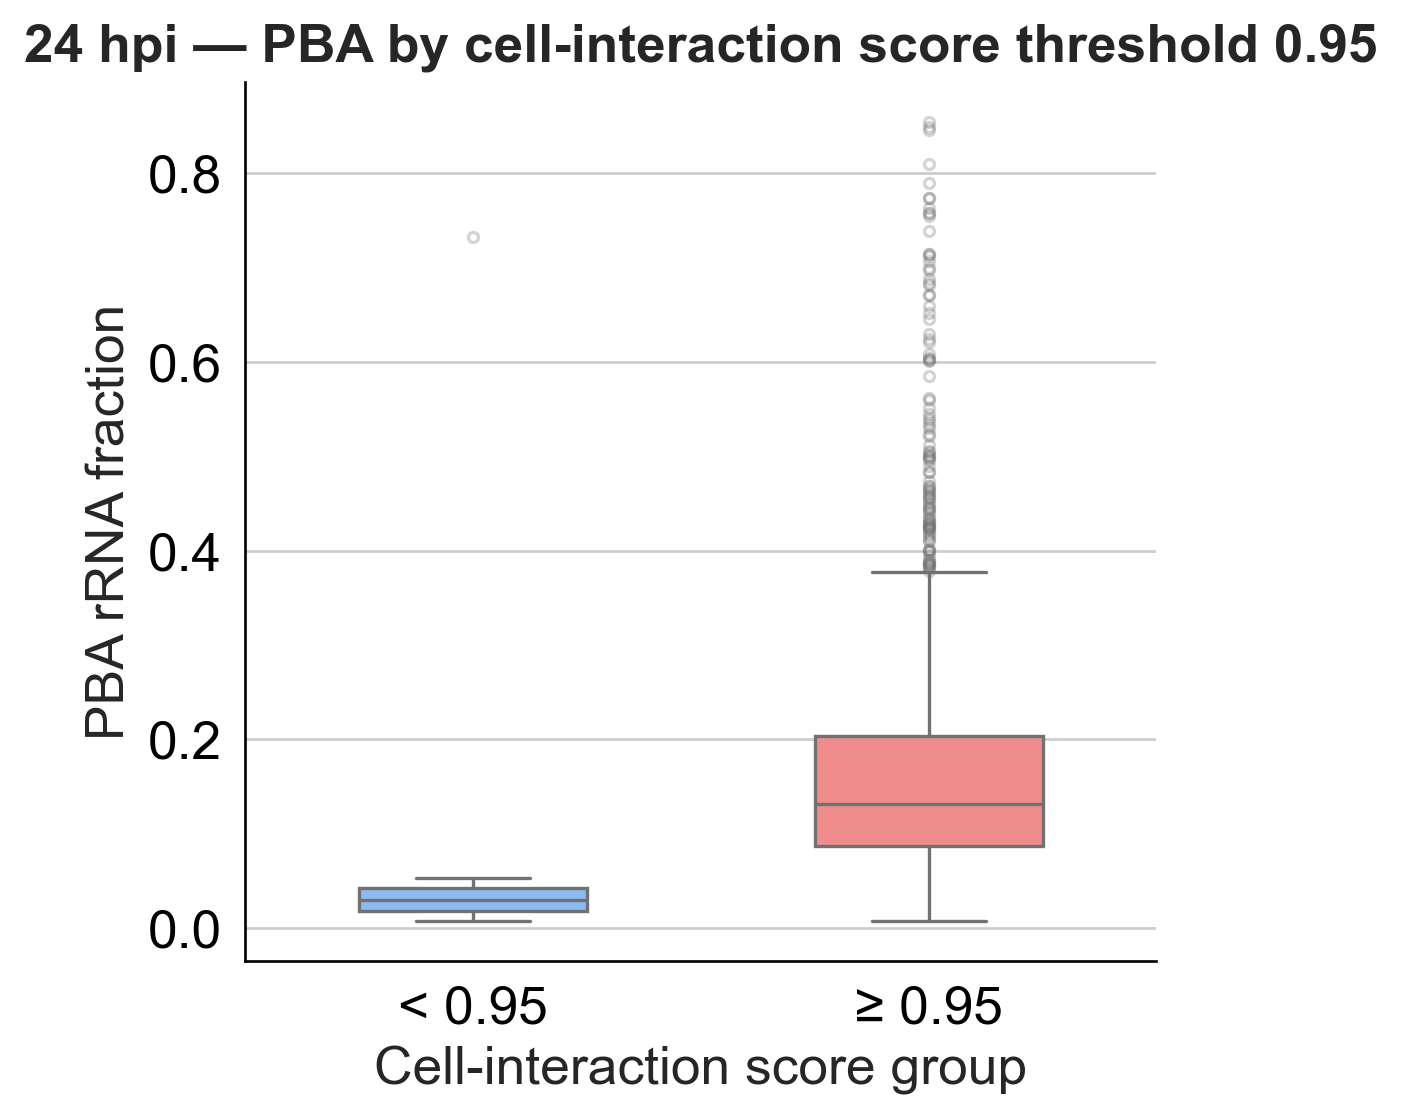

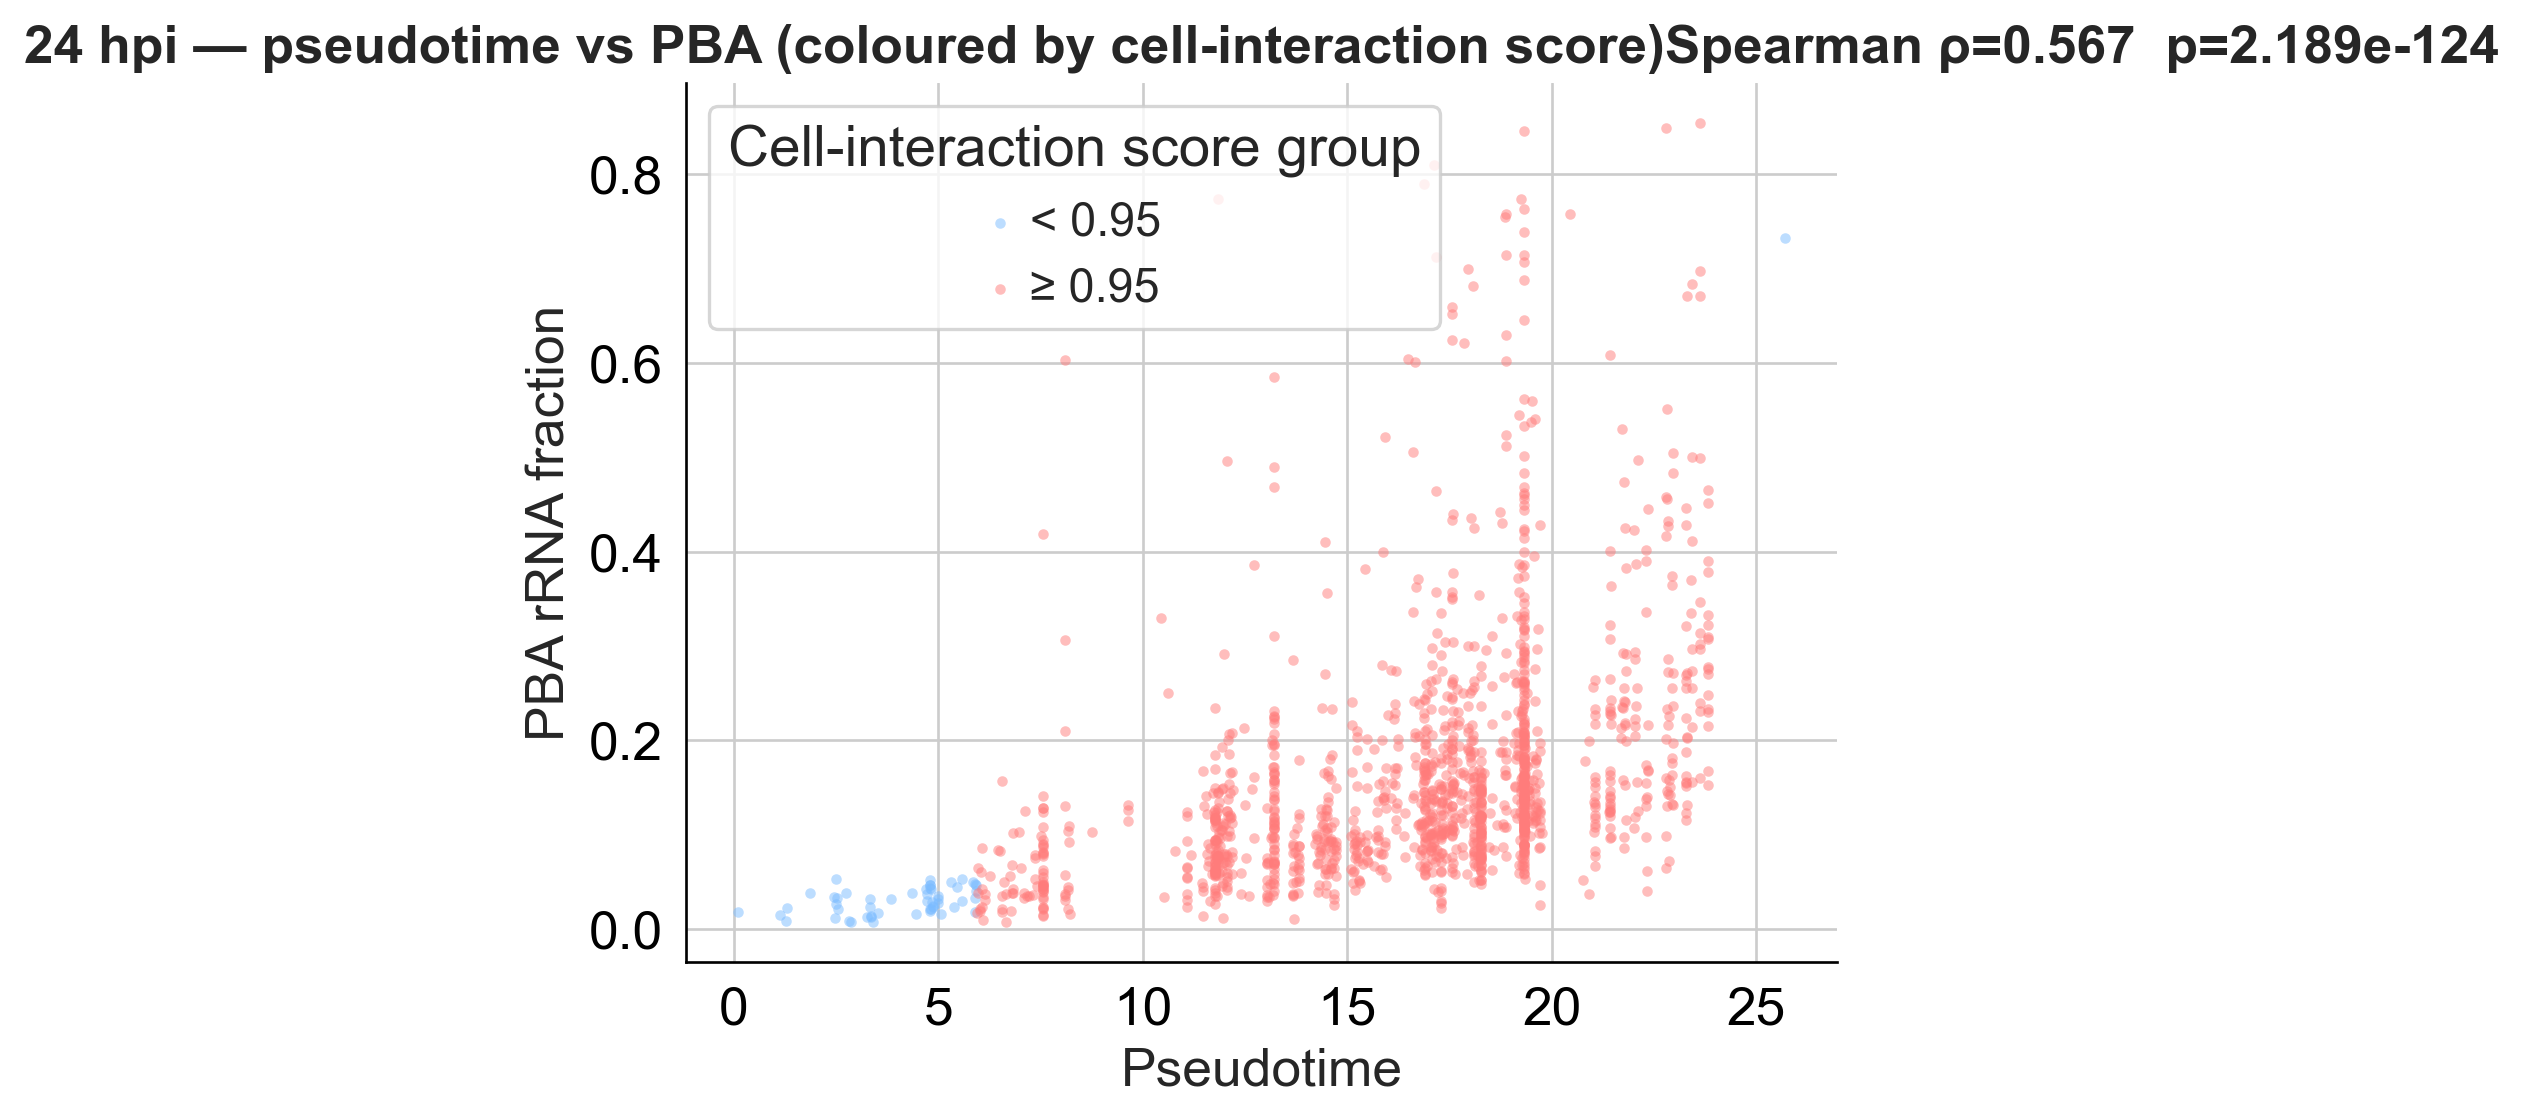

30 hpi  |  n_low=116  n_high=373  median_low=0.032  median_high=0.217  p=1.294e-39


/tmp/ipykernel_2907822/1831174998.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


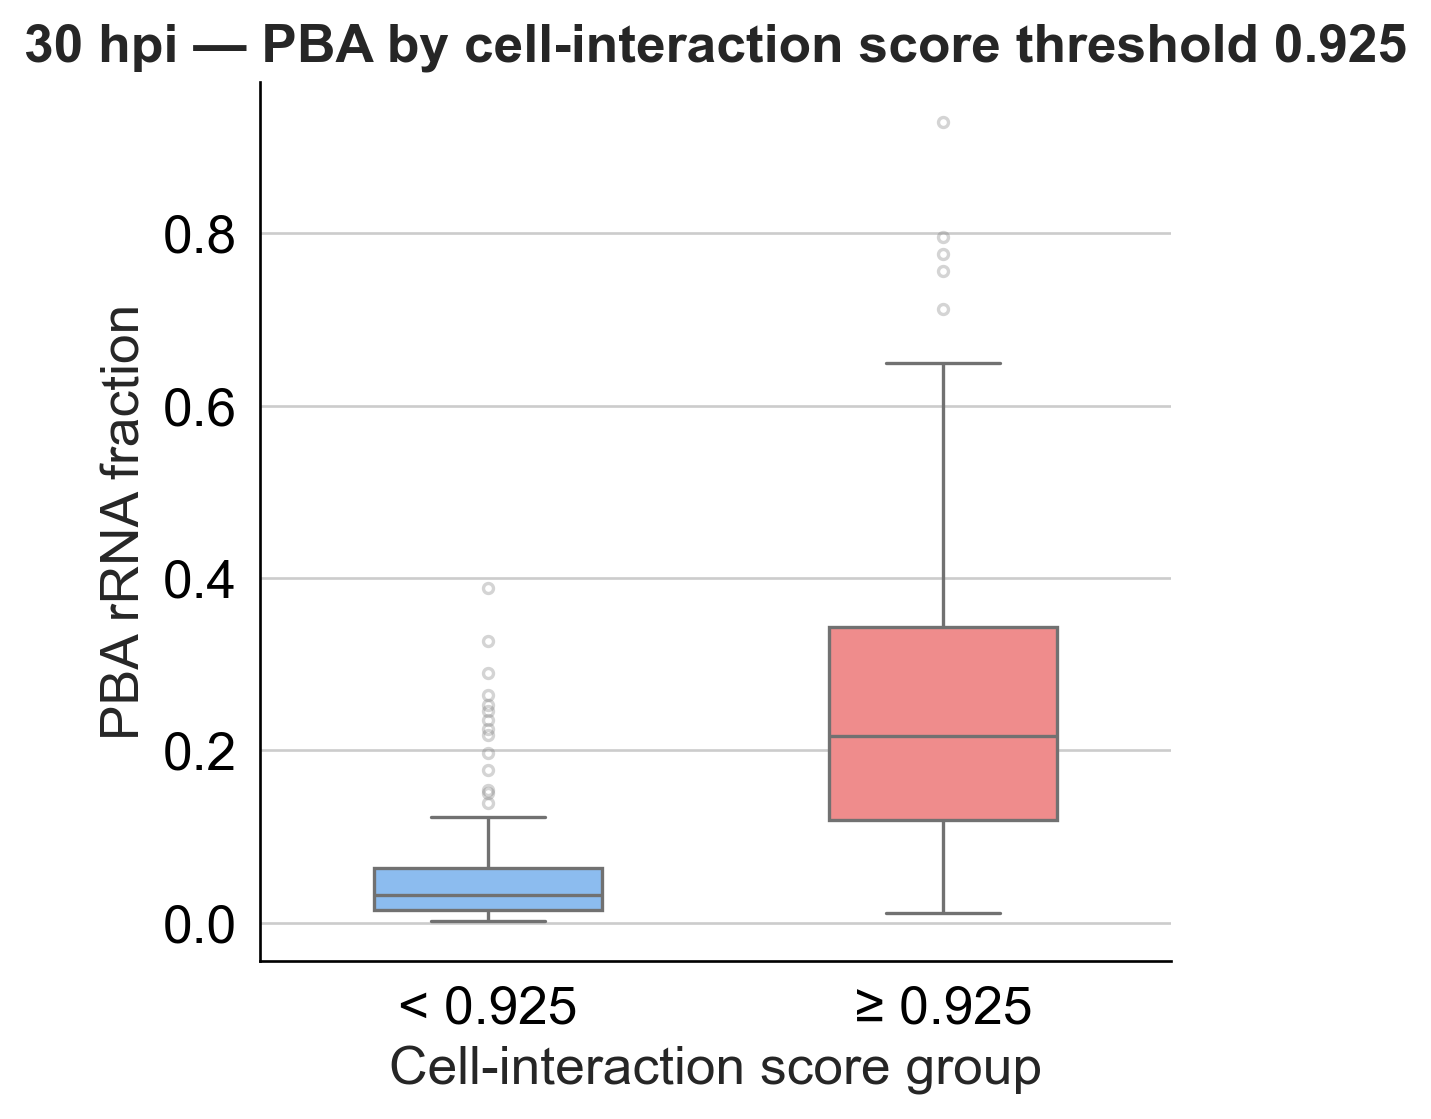

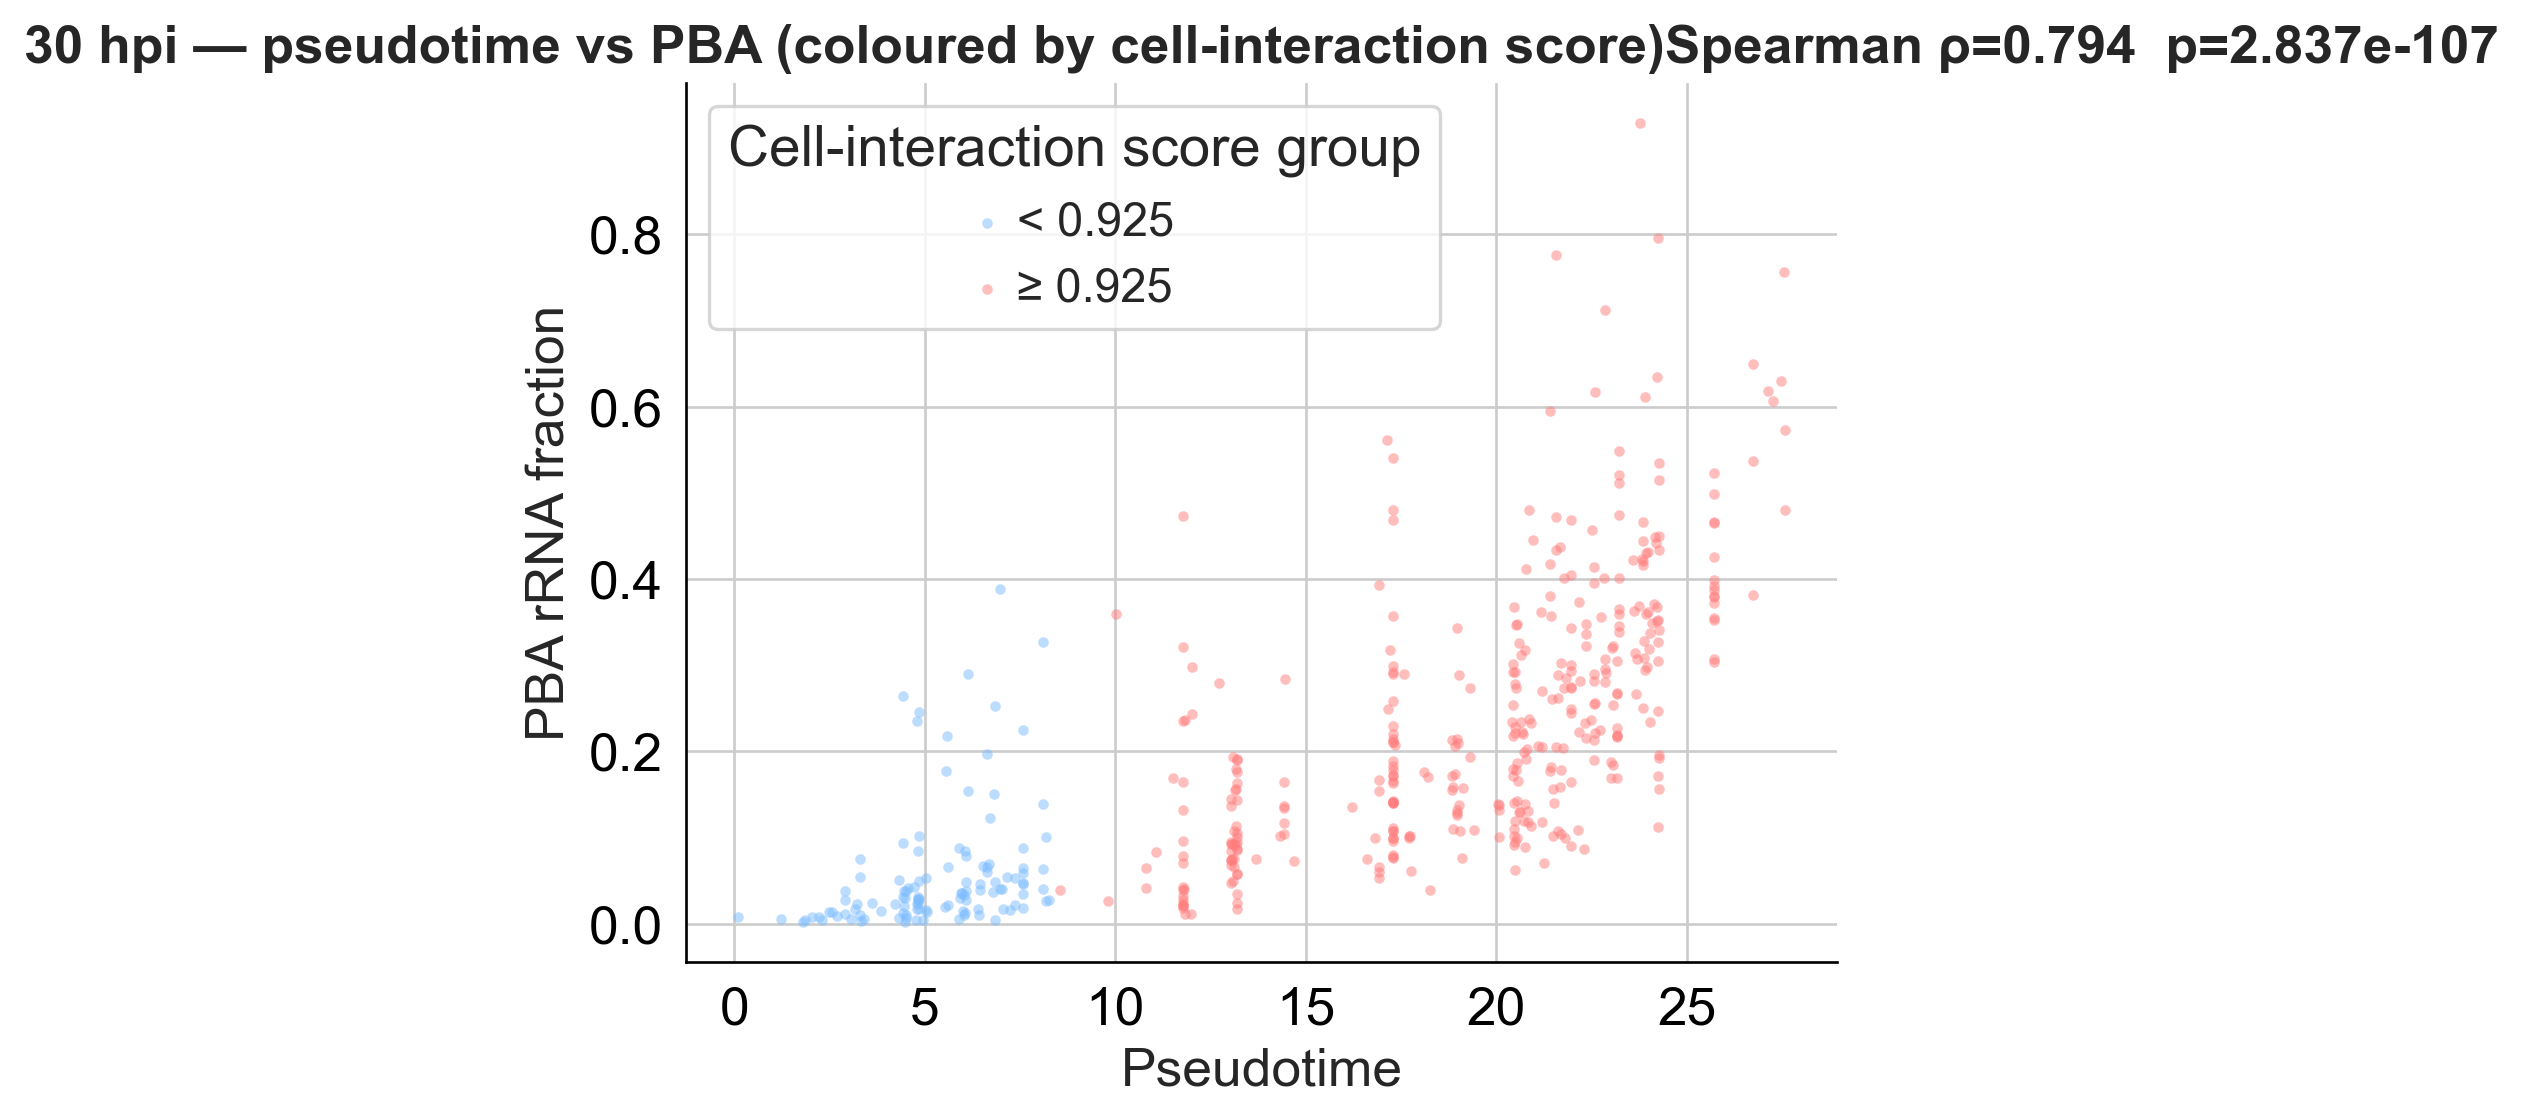

In [33]:
# Per time-point threshold split + pseudotime vs PBA scatter
THRESH_24 = 0.95
THRESH_30 = 0.925

adata_24 = adata_2430[adata_2430.obs["time_int"] == 24.0].copy()
adata_30 = adata_2430[adata_2430.obs["time_int"] == 30.0].copy()

for tp_adata, thresh, tp_label in [
    (adata_24, THRESH_24, "24 hpi"),
    (adata_30, THRESH_30, "30 hpi"),
]:
    low_mask  = tp_adata.obs["proj_pearson_cell"] <  thresh
    high_mask = tp_adata.obs["proj_pearson_cell"] >= thresh
    low_label  = f"< {thresh}"
    high_label = f"≥ {thresh}"
    tp_adata.obs["score_group"] = np.where(low_mask, low_label, high_label)

    low_pba  = tp_adata.obs.loc[low_mask,  PBA_COL]
    high_pba = tp_adata.obs.loc[high_mask, PBA_COL]
    _, p_mw = stats.mannwhitneyu(low_pba, high_pba, alternative="two-sided")
    print(f"{tp_label}  |  n_low={low_mask.sum()}  n_high={high_mask.sum()}  "
          f"median_low={low_pba.median():.3f}  median_high={high_pba.median():.3f}  p={p_mw:.3e}")

    safe_tp = tp_label.replace(" ", "")
    palette_grp = {low_label: "#7bbcff", high_label: "#ff7c7b"}

    # --- figure 1: boxplot low vs high ---
    fig, ax = plt.subplots(figsize=(5, 5))
    sns.boxplot(
        data=tp_adata.obs, x="score_group", y=PBA_COL,
        order=[low_label, high_label], palette=palette_grp,
        width=0.5, ax=ax,
        flierprops=dict(marker="o", markersize=3, alpha=0.3),
    )
    ax.set_xlabel("Cell-interaction score group", fontsize=16)
    ax.set_ylabel("PBA rRNA fraction", fontsize=16)
    ax.set_title(f"{tp_label} — PBA by cell-interaction score threshold {thresh}", fontsize=16)
    ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    plt.savefig(os.path.join(outdir, f"pba_boxplot_threshold_{safe_tp}.png"),
                dpi=150, bbox_inches="tight")
    plt.show()

    # --- figure 2: pseudotime vs PBA coloured by score group ---
    r, p_sp = stats.spearmanr(tp_adata.obs["pseudotime"], tp_adata.obs[PBA_COL])
    fig, ax = plt.subplots(figsize=(6, 5))
    for grp, color in palette_grp.items():
        mask = tp_adata.obs["score_group"] == grp
        ax.scatter(
            tp_adata.obs.loc[mask, "pseudotime"],
            tp_adata.obs.loc[mask, PBA_COL],
            c=color, s=10, alpha=0.5, label=grp, linewidths=0,
        )
    ax.set_xlabel("Pseudotime", fontsize=16)
    ax.set_ylabel("PBA rRNA fraction", fontsize=16)
    ax.set_title(
        f"{tp_label} — pseudotime vs PBA (coloured by cell-interaction score)"
        f"Spearman ρ={r:.3f}  p={p_sp:.3e}",
        fontsize=16,
    )
    ax.legend(title="Cell-interaction score group", fontsize=14)
    ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    plt.savefig(os.path.join(outdir, f"pba_scatter_pseudotime_{safe_tp}.png"),
                dpi=150, bbox_inches="tight")
    plt.show()


30 hpi -- cell score + pseudotime clusters:
score_pt_cluster
High cell-interaction score cluster    367
Low cell-interaction score cluster     122
Name: count, dtype: int64
                                    proj_pearson_cell                      \
                                                 mean       min       max   
score_pt_cluster                                                            
High cell-interaction score cluster          0.986150  0.934500  0.999172   
Low cell-interaction score cluster           0.910795  0.892241  0.950178   

                                    pseudotime                        
                                          mean        min        max  
score_pt_cluster                                                      
High cell-interaction score cluster  19.780244  11.515740  27.572399  
Low cell-interaction score cluster    5.579618   0.105265  11.076580  


/tmp/ipykernel_2907822/410762191.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/tmp/ipykernel_2907822/410762191.py:37: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(


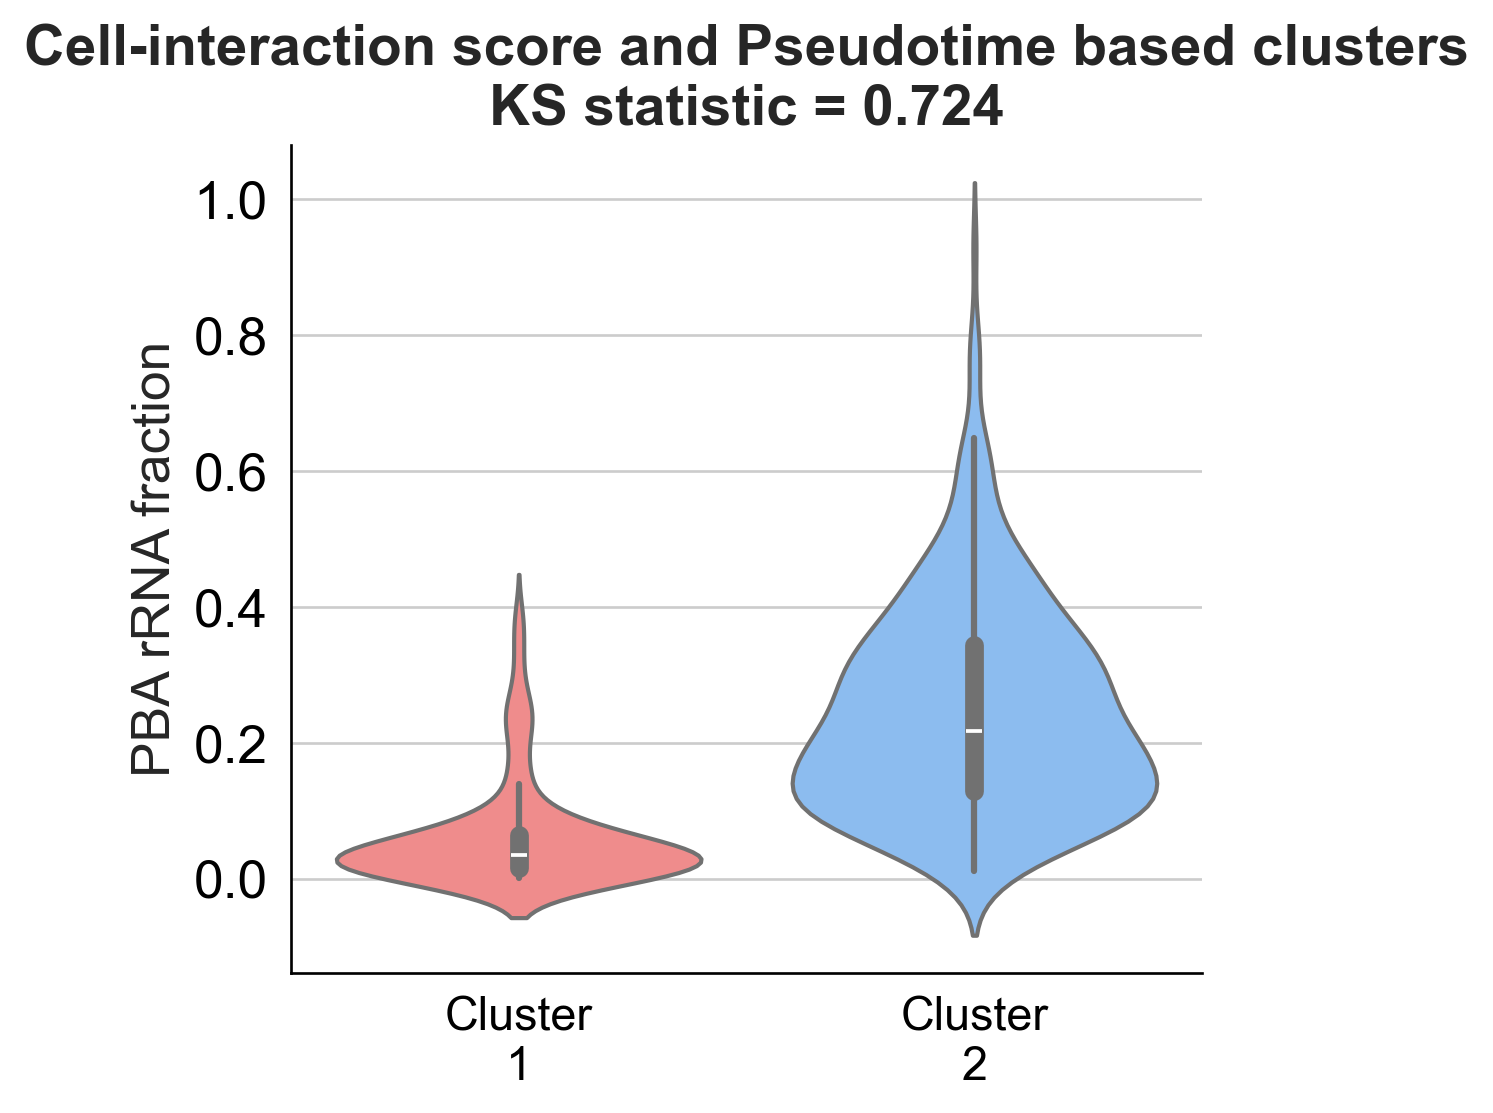

In [53]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from scipy.stats import ks_2samp
# Cluster 30 hpi cells into 2 groups based on cell score AND pseudotime
feat_cols_30 = adata_30.obs[["proj_pearson_cell", "pseudotime"]].values
X_feat_30 = StandardScaler().fit_transform(feat_cols_30)
km30_sp = KMeans(n_clusters=2, random_state=0, n_init=10).fit(X_feat_30)

# relabel clusters by mean cell score so names are interpretable
cluster_means_sp = adata_30.obs["proj_pearson_cell"].groupby(km30_sp.labels_).mean().sort_values()
label_map_sp = {cluster_means_sp.index[0]: "Low cell-interaction score cluster", cluster_means_sp.index[1]: "High cell-interaction score cluster"}
adata_30.obs["score_pt_cluster"] = [label_map_sp[l] for l in km30_sp.labels_]

print("30 hpi -- cell score + pseudotime clusters:")
print(adata_30.obs["score_pt_cluster"].value_counts())
print(adata_30.obs.groupby("score_pt_cluster")[["proj_pearson_cell", "pseudotime"]].agg(["mean", "min", "max"]))

low_vals_sp  = adata_30.obs.loc[adata_30.obs["score_pt_cluster"] == "Low cell-interaction score cluster",  PBA_COL]
high_vals_sp = adata_30.obs.loc[adata_30.obs["score_pt_cluster"] == "High cell-interaction score cluster", PBA_COL]
ks_stat_sp, p_sp = ks_2samp(low_vals_sp, high_vals_sp)

fig, ax = plt.subplots(figsize=(5, 5))
palette_cluster = {
    "Low cell-interaction score cluster": "#ff7c7b",
    "High cell-interaction score cluster": "#7bbcff"
}

sns.violinplot(
    data=adata_30.obs,
    x="score_pt_cluster",
    y=PBA_COL,
    order=["Low cell-interaction score cluster", "High cell-interaction score cluster"],
    palette=palette_cluster,
    inner="box",
    ax=ax,
)

ax.set_xticklabels(
    ["Cluster\n1", "Cluster\n2"],
    fontsize=14
)

ax.set_title(
    f"Cell-interaction score and Pseudotime based clusters\nKS statistic = {ks_stat_sp:.3f}",
    fontsize=17
)
ax.set_xlabel("")
ax.set_ylabel("PBA rRNA fraction", fontsize=16)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig(
    os.path.join(outdir, "violin_pba_by_score_pt_cluster_30hpi.png"),
    dpi=150,
    bbox_inches="tight",
)
plt.show()

30 hpi -- pseudotime clusters:
pt_cluster
High pseudotime cluster    297
Low pseudotime cluster     192
Name: count, dtype: int64
                              mean        min        max
pt_cluster                                              
High pseudotime cluster  21.414263  16.204604  27.572399
Low pseudotime cluster    8.229307   0.105265  14.685297


/tmp/ipykernel_2907822/3726730571.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/tmp/ipykernel_2907822/3726730571.py:34: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(


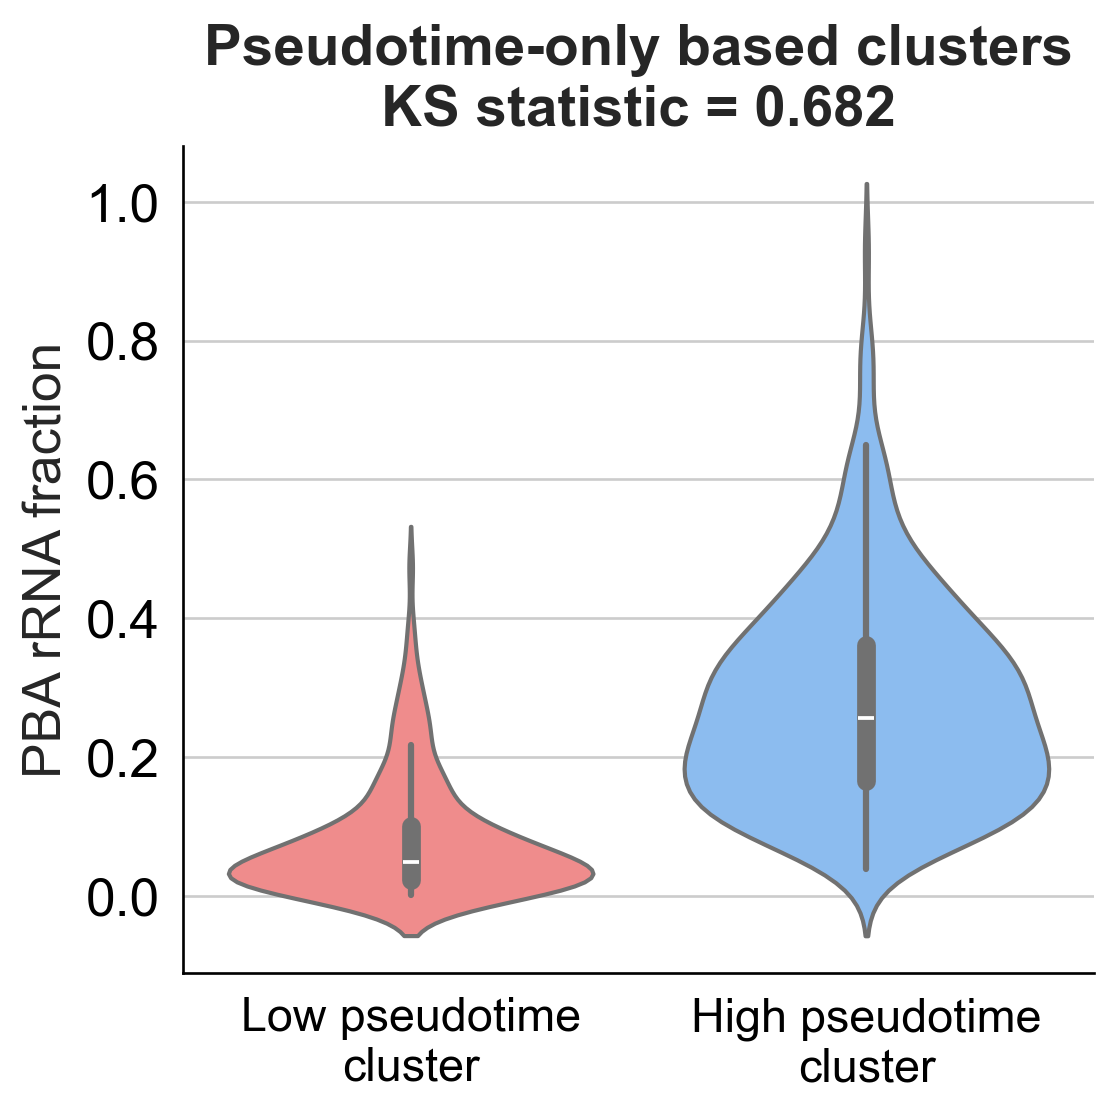

In [52]:
# Cluster 30 hpi cells into 2 groups based on pseudotime only
X_pt_30 = adata_30.obs["pseudotime"].values.reshape(-1, 1)
km30_pt = KMeans(n_clusters=2, random_state=0, n_init=10).fit(X_pt_30)

# relabel clusters by mean pseudotime so names are interpretable
cluster_means_pt = pd.Series(X_pt_30.ravel()).groupby(km30_pt.labels_).mean().sort_values()
label_map_pt = {cluster_means_pt.index[0]: "Low pseudotime cluster", cluster_means_pt.index[1]: "High pseudotime cluster"}
adata_30.obs["pt_cluster"] = [label_map_pt[l] for l in km30_pt.labels_]

print("30 hpi -- pseudotime clusters:")
print(adata_30.obs["pt_cluster"].value_counts())
print(adata_30.obs.groupby("pt_cluster")["pseudotime"].agg(["mean", "min", "max"]))

low_vals_pt  = adata_30.obs.loc[adata_30.obs["pt_cluster"] == "Low pseudotime cluster",  PBA_COL]
high_vals_pt = adata_30.obs.loc[adata_30.obs["pt_cluster"] == "High pseudotime cluster", PBA_COL]
ks_stat_pt, p_pt = ks_2samp(low_vals_pt, high_vals_pt)

fig, ax = plt.subplots(figsize=(5, 5))
palette_cluster = {
    "Low pseudotime cluster": "#ff7c7b",
    "High pseudotime cluster": "#7bbcff"
}

sns.violinplot(
    data=adata_30.obs,
    x="pt_cluster",
    y=PBA_COL,
    order=["Low pseudotime cluster", "High pseudotime cluster"],
    palette=palette_cluster,
    inner="box",
    ax=ax,
)

ax.set_xticklabels(
    ["Low pseudotime\ncluster", "High pseudotime\ncluster"],
    fontsize=14
)

ax.set_title(f"Pseudotime-only based clusters\nKS statistic = {ks_stat_pt:.3f}", fontsize=17)
ax.set_xlabel("")
ax.set_ylabel("PBA rRNA fraction", fontsize=16)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig(
    os.path.join(outdir, "violin_pba_by_pt_cluster_30hpi.png"),
    dpi=150,
    bbox_inches="tight",
)
plt.show()

Category counts:
category
36 hpi  ≥ 0.9                893
36 hpi  < 0.9\nProductive    114
36 hpi  < 0.9\nAbortive       76
  '36 hpi  < 0.9\nAbortive' vs '36 hpi  < 0.9\nProductive': p = 1.36e-01
  '36 hpi  < 0.9\nAbortive' vs '36 hpi  ≥ 0.9': p = 4.18e-46
  '36 hpi  < 0.9\nProductive' vs '36 hpi  ≥ 0.9': p = 6.38e-59


/tmp/ipykernel_2907822/2392567762.py:36: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


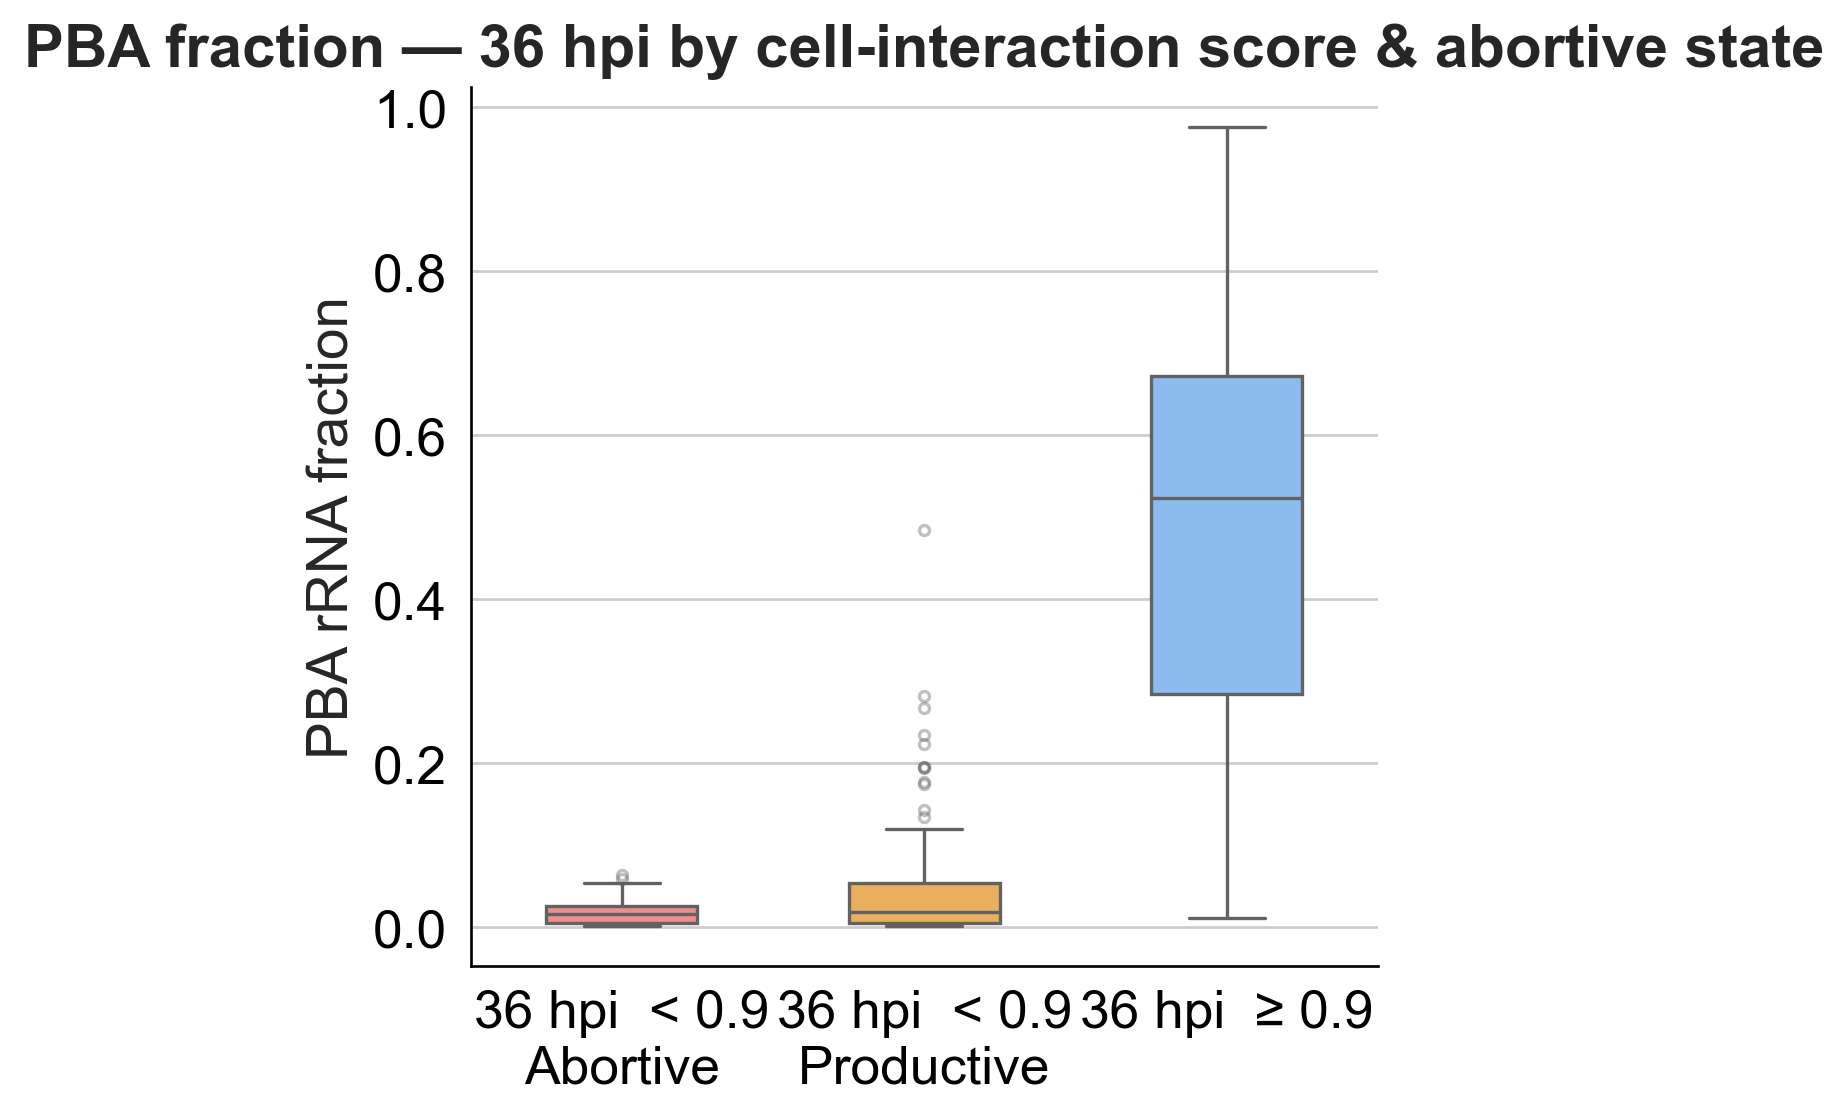

In [40]:
obs36 = adata_36.obs.copy()

def categorize(row):
  if row["proj_spearman_cell"] >= SCORE_THRESHOLD:
      return f"36 hpi  ≥ {SCORE_THRESHOLD}"
  elif row["abortive_state"] == "Abortive":
      return f"36 hpi  < {SCORE_THRESHOLD}\nAbortive"
  else:
      return f"36 hpi  < {SCORE_THRESHOLD}\nProductive"

obs36["category"] = obs36.apply(categorize, axis=1)

cat_order = [
  f"36 hpi  < {SCORE_THRESHOLD}\nAbortive",
  f"36 hpi  < {SCORE_THRESHOLD}\nProductive",
  f"36 hpi  ≥ {SCORE_THRESHOLD}",
]
palette = {
  f"36 hpi  < {SCORE_THRESHOLD}\nAbortive":   "#ff7c7b",
  f"36 hpi  < {SCORE_THRESHOLD}\nProductive": "#ffb347",
  f"36 hpi  ≥ {SCORE_THRESHOLD}":             "#7bbcff",
}

print("Category counts:")
print(obs36["category"].value_counts().to_string())

groups = {cat: obs36.loc[obs36["category"] == cat, PBA_COL] for cat in cat_order}
for i, c1 in enumerate(cat_order):
  for c2 in cat_order[i+1:]:
      _, p = stats.ranksums(groups[c1], groups[c2])
      print(f"  {c1!r} vs {c2!r}: p = {p:.2e}")

positions = [0, 0.6, 1.2]

fig, ax = plt.subplots(figsize=(5, 5))
sns.boxplot(
  data=obs36, x="category", y=PBA_COL,
  order=cat_order, palette=palette, width=0.5, ax=ax,
  flierprops=dict(marker="o", markersize=3, alpha=0.4),
)
ax.set_xticks(range(len(cat_order)))
ax.set_xticklabels(cat_order)
# shrink the x axis limits to bring boxes closer
ax.set_xlim(-0.5, len(cat_order) - 0.5)
ax.set_xlabel("", fontsize=16)
ax.set_ylabel("PBA rRNA fraction", fontsize=17)
ax.set_title("PBA fraction — 36 hpi by cell-interaction score & abortive state", fontsize=18)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(os.path.join(outdir, "boxplot_pba_3cat_36hpi.png"), dpi=150, bbox_inches="tight")
plt.show()


36 hpi -- cell score clusters:
score_cluster
High score cluster    859
Low score cluster     224
Name: count, dtype: int64
                        mean       min       max
score_cluster                                   
High score cluster  0.978414  0.926053  0.998127
Low score cluster   0.852616  0.825921  0.913567


/tmp/ipykernel_2907822/4070975899.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


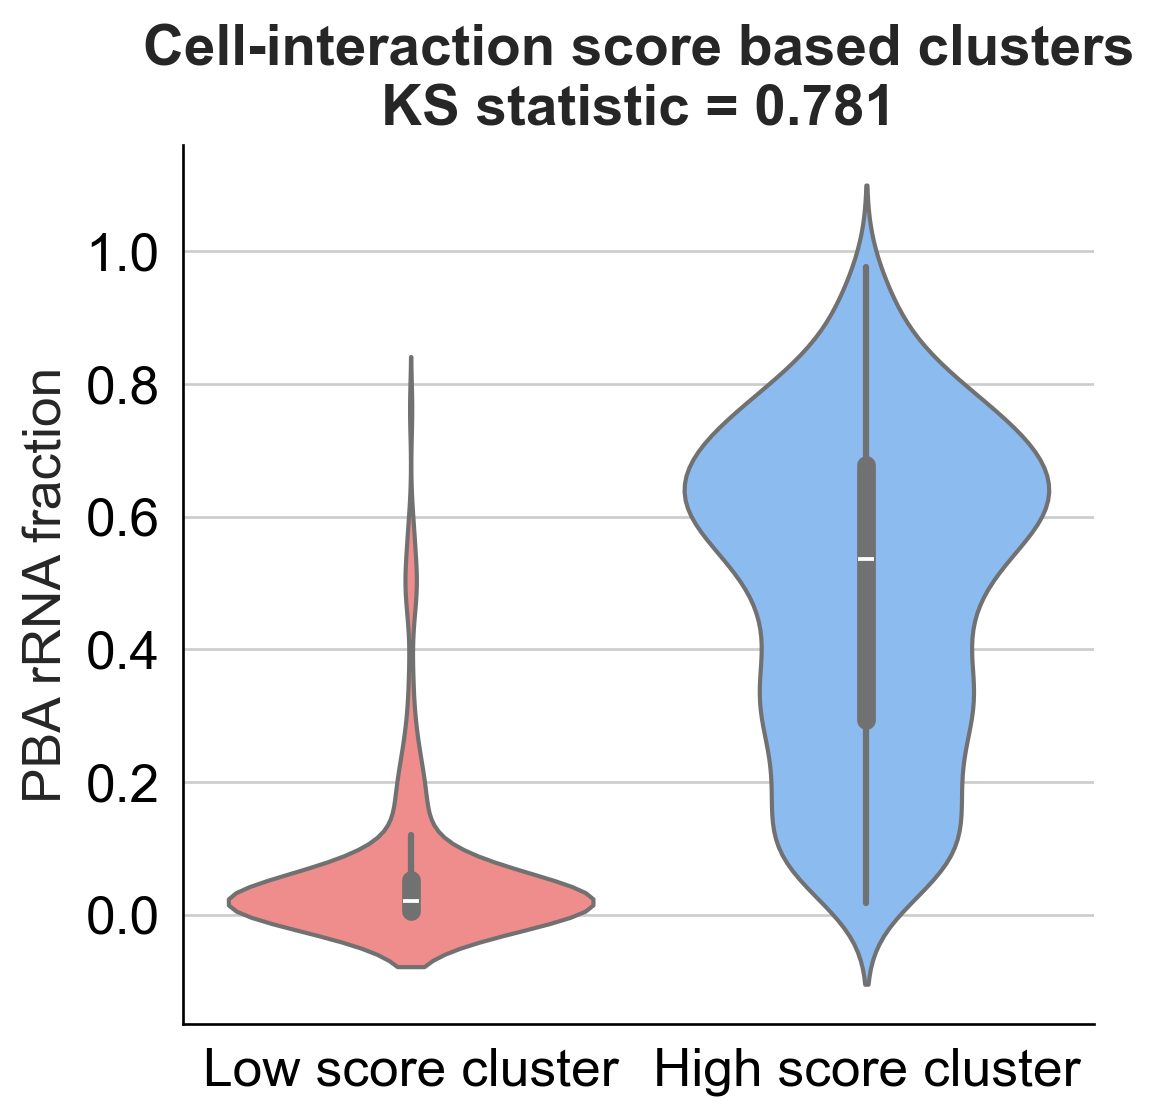

In [51]:
from sklearn.cluster import KMeans
from scipy.stats import ks_2samp

# Cluster 36 hpi cells into 2 groups based on their cell score
X_score_36 = adata_36.obs["proj_pearson_cell"].values.reshape(-1, 1)
km36 = KMeans(n_clusters=2, random_state=0, n_init=10).fit(X_score_36)

# relabel clusters by mean score so names are interpretable
cluster_means_36 = pd.Series(X_score_36.ravel()).groupby(km36.labels_).mean().sort_values()
label_map_36 = {cluster_means_36.index[0]: "Low score cluster", cluster_means_36.index[1]: "High score cluster"}
adata_36.obs["score_cluster"] = [label_map_36[l] for l in km36.labels_]

print("36 hpi -- cell score clusters:")
print(adata_36.obs["score_cluster"].value_counts())
print(adata_36.obs.groupby("score_cluster")["proj_pearson_cell"].agg(["mean", "min", "max"]))

low_vals_36  = adata_36.obs.loc[adata_36.obs["score_cluster"] == "Low score cluster",  PBA_COL]
high_vals_36 = adata_36.obs.loc[adata_36.obs["score_cluster"] == "High score cluster", PBA_COL]
ks_stat_36, p_36 = ks_2samp(low_vals_36, high_vals_36)

fig, ax = plt.subplots(figsize=(5, 5))
palette_cluster = {"Low score cluster": "#ff7c7b", "High score cluster": "#7bbcff"}
sns.violinplot(
    data=adata_36.obs, x="score_cluster", y=PBA_COL,
    order=["Low score cluster", "High score cluster"],
    palette=palette_cluster, inner="box", ax=ax,
)
ax.set_title(f"Cell-interaction score based clusters\nKS statistic = {ks_stat_36:.3f}", fontsize=17)
ax.set_xlabel("", fontsize=16)
ax.set_ylabel("PBA rRNA fraction", fontsize=16)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(os.path.join(outdir, "violin_pba_by_scorecluster_36hpi.png"), dpi=150, bbox_inches="tight")
plt.show()

/tmp/ipykernel_2907822/521353275.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


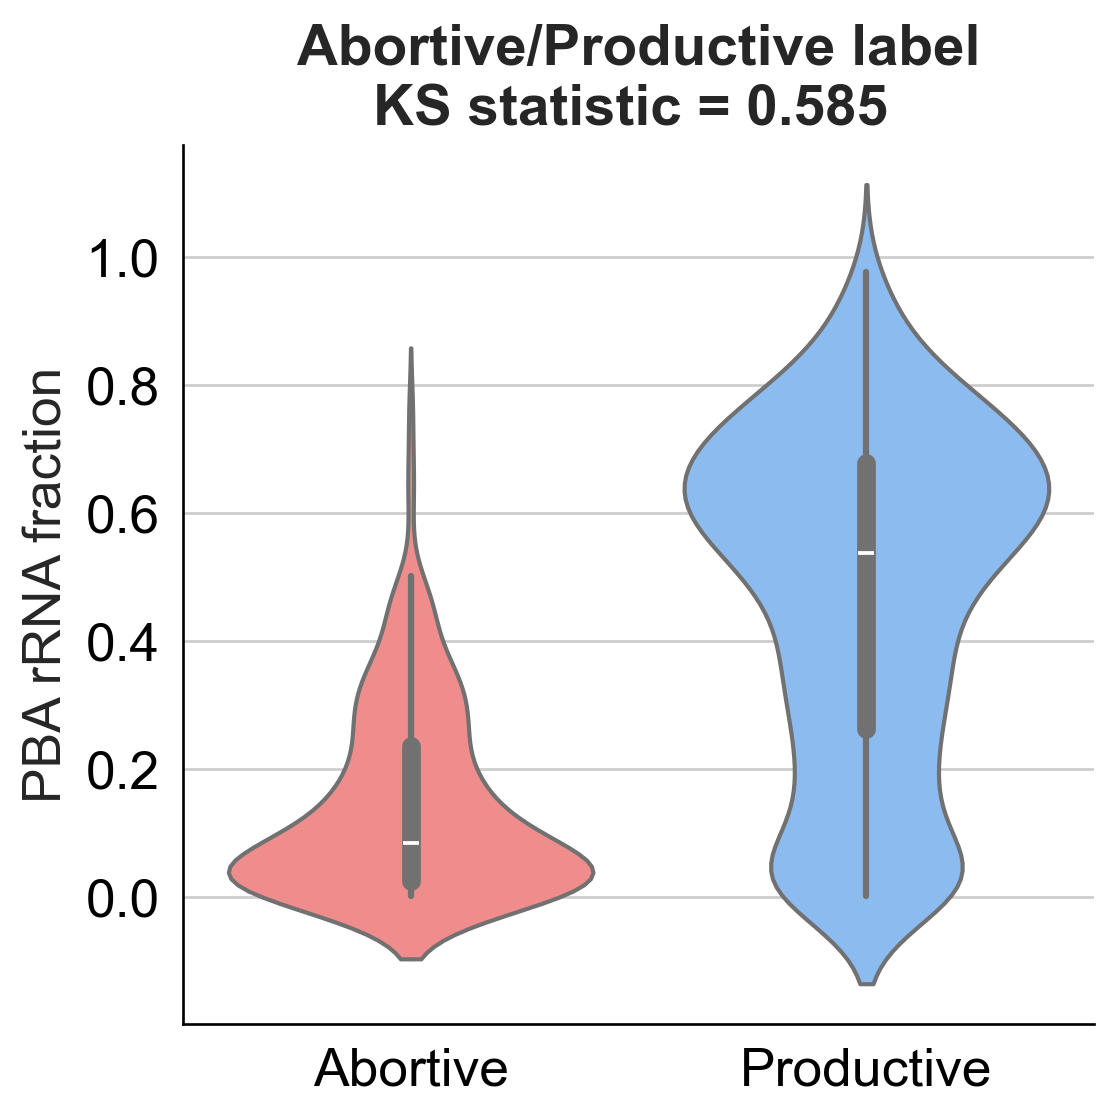

Abortive  (n=234): median = 0.0845
Productive (n=849): median = 0.5375


In [42]:
from scipy.stats import ks_2samp

# PBA fraction: abortive vs productive (36 hpi)
ab_vals_36 = adata_36.obs.loc[adata_36.obs["abortive_state"] == "Abortive",  PBA_COL]
pr_vals_36 = adata_36.obs.loc[adata_36.obs["abortive_state"] == "Productive", PBA_COL]
ks_stat_ab, p_ab = ks_2samp(ab_vals_36, pr_vals_36)

fig, ax = plt.subplots(figsize=(5, 5))
palette_ab = {"Abortive": "#ff7c7b", "Productive": "#7bbcff"}
sns.violinplot(
    data=adata_36.obs, x="abortive_state", y=PBA_COL,
    order=["Abortive", "Productive"],
    palette=palette_ab, inner="box", ax=ax,
)
ax.set_title(f"Abortive/Productive label\nKS statistic = {ks_stat_ab:.3f} ", fontsize=17)
ax.set_xlabel("", fontsize=16)
ax.set_ylabel("PBA rRNA fraction", fontsize=16)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(os.path.join(outdir, "violin_pba_by_abortive_state_36hpi.png"), dpi=150, bbox_inches="tight")
plt.show()

print(f"Abortive  (n={len(ab_vals_36)}): median = {ab_vals_36.median():.4f}")
print(f"Productive (n={len(pr_vals_36)}): median = {pr_vals_36.median():.4f}")